<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-03/lab-007-building-and-training.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
**Author:** Marcin Płodzień
<hr/>

# Lab 007 — Building and training neural networks in PyTorch

We assume familiarity with PyTorch tensors, the classes `nn.Linear`, `nn.Sequential` and `nn.Module`, and with how autograd computes gradients.
This notebook combines them and treats in detail the two things that all neural-network code relies on:

1. **How a network is built.** PyTorch offers two ways: the container `nn.Sequential` (layers applied one after another) and a
   class derived from `nn.Module` (any computation written in a method `forward`). For a series of architectures of increasing size we
   draw the network, build it in **both** ways (and, for Example A, a third one with explicit parameters and `einsum`), check that both give the same function, and follow the forward pass by hand.
   Then we construct networks automatically from a list of layer sizes, and build architectures that `nn.Sequential` cannot express.
2. **How a network is trained.** The training loop is taken apart step by step: what each line does to the parameters and their gradients,
   full-batch and mini-batch training, validation, saving the result, and the most common bugs.

**Plan**
1. Notation: a network as a composition of layers
2. A function that draws network architectures
3. Example A: one input, one hidden layer with $N$ nodes, one output
4. Example B: two hidden layers
5. Example C: several inputs and several outputs
6. Example D: a classifier for images
7. Building networks automatically from a list of layer sizes
8. Architectures beyond `nn.Sequential`
9. Inspecting a model
10. The training loop in detail
11. Mini-batches, epochs and validation
12. A reusable training function; saving and loading a model
13. Common bugs
14. Training the image classifier on MNIST
15. Summary
16. Exercises (with solutions)

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. The required packages (`numpy`, `matplotlib`, `torch`, `torchvision`) are pre-installed in Colab; no `pip install` required.
> 4. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)      # fixes the random numbers (initial parameters, data); the value 0 is arbitrary
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cpu


<hr/>
## 1. Notation: a network as a composition of layers

A fully connected (dense) network with layer sizes $n_0, n_1, \dots, n_L$ maps an input $\mathbf x\in\mathbb R^{n_0}$ to an output in $\mathbb R^{n_L}$ through
$$\mathbf h^{(0)} = \mathbf x,\qquad \mathbf h^{(l)} = \sigma\big(\mathbf W^{(l)}\mathbf h^{(l-1)} + \mathbf b^{(l)}\big),\quad l = 1,\dots,L-1,\qquad
f(\mathbf x) = \mathbf W^{(L)}\mathbf h^{(L-1)} + \mathbf b^{(L)} .$$
- $\mathbf W^{(l)}$ is a matrix of shape $n_l\times n_{l-1}$ and $\mathbf b^{(l)}$ a vector of length $n_l$: layer $l$ has $n_l(n_{l-1}+1)$ parameters.
- $\sigma$ is applied element-wise in the **hidden** layers. The last layer usually has no activation (regression), or one adapted to the task (e.g. softmax for classification, which in PyTorch is usually applied inside the loss function rather than as a layer; see Section 14.2).
- In PyTorch one layer $\mathbf h \mapsto \mathbf W\mathbf h + \mathbf b$ is `nn.Linear(n_in, n_out)`; it stores `weight` with shape `(n_out, n_in)` and `bias` with shape `(n_out,)`.
- Data are processed in **batches**: an input tensor has shape `(B, n_0)`, one row per sample, and the output has shape `(B, n_L)`.
  For a batch, the layer computes `H_out = H_in @ W.T + b`. The transpose appears because every sample is a **row** of `H_in`: the row form of
  $\mathbf h_{\rm out} = \mathbf W\mathbf h_{\rm in} + \mathbf b$ is $\mathbf h_{\rm out}^T = \mathbf h_{\rm in}^T\mathbf W^T + \mathbf b^T$, applied to all rows at once.

The list $[n_0, n_1, \dots, n_L]$ together with the choice of $\sigma$ is the **architecture** of the network.

<hr/>
## 2. A function that draws network architectures

Every architecture in this notebook is drawn with the following function. Each circle is a node (neuron), each grey line a weight.
The function uses only basic plotting commands (`plot`, `scatter`, `text`); its code does not need to be studied to follow the rest of the notebook.
Layers with more than `max_nodes` nodes are drawn shortened, with "..." marking the omitted nodes.
The parameter count in the title is computed from the formula $\sum_l n_l(n_{l-1}+1)$ above.

In [2]:
def draw_network(layer_sizes, activations=None, title="", max_nodes=10, ax=None,
                 input_labels=None, output_labels=None):
    """
    Draw a fully connected network.
    layer_sizes : e.g. [1, 8, 1] = 1 input, one hidden layer with 8 nodes, 1 output
    activations : names of the activation functions of the hidden layers, e.g. ["tanh"]
    max_nodes   : larger layers are drawn with max_nodes nodes and a vertical "..." in the middle
    input_labels, output_labels : optional texts written next to the input and output nodes, e.g. ["$x$"]
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(1.9 * len(layer_sizes) + 1, 4.2))
    n_layers = len(layer_sizes)
    positions = []                                   # list of (x, y) arrays, one per layer
    for i, n in enumerate(layer_sizes):
        shown = min(n, max_nodes)
        y = np.linspace(-1, 1, shown) if shown > 1 else np.array([0.0])
        positions.append((np.full(shown, float(i)), y * min(1.0, shown / max_nodes + 0.15)))
    # connections between neighbouring layers
    for i in range(n_layers - 1):
        (x0, y0), (x1, y1) = positions[i], positions[i + 1]
        for a in y0:
            for b in y1:
                ax.plot([x0[0], x1[0]], [a, b], color="0.7", lw=0.6, zorder=1)
    # nodes and labels
    for i, (n, (xs, ys)) in enumerate(zip(layer_sizes, positions)):
        if i == 0:
            color, name = "C2", "input"
        elif i == n_layers - 1:
            color, name = "C3", "output"
        else:
            act = activations[i - 1] if activations is not None else ""
            color, name = "C0", f"hidden {i}" + (f"\n{act}" if act else "")
        ax.scatter(xs, ys, s=260, color=color, edgecolor="k", zorder=3)
        if n > max_nodes:                            # mark omitted nodes
            ax.text(xs[0] + 0.2, 0.0, "...", rotation=90, fontsize=14, va="center", ha="center",
                    bbox=dict(facecolor="white", edgecolor="none", pad=1), zorder=4)
        ax.text(xs[0], -1.35, f"{name}\n{n} node" + ("s" if n > 1 else ""), ha="center", va="top", fontsize=10)
    if input_labels is not None:
        for y, lab in zip(positions[0][1], input_labels):
            ax.text(-0.18, y, lab, ha="right", va="center", fontsize=12)
    if output_labels is not None:
        for y, lab in zip(positions[-1][1], output_labels):
            ax.text(n_layers - 1 + 0.18, y, lab, ha="left", va="center", fontsize=12)
    n_params = sum(n_in * n_out + n_out for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]))
    ax.set_title((title + "\n" if title else "") + f"layer sizes {layer_sizes},  {n_params} parameters", fontsize=11)
    ax.set_xlim(-0.8, n_layers - 0.2); ax.set_ylim(-2.1, 1.3)
    ax.axis("off")
    return ax

<hr/>
## 3. Example A: one input, one hidden layer with $N$ nodes, one output

This is the network of the Universal Approximation Theorem from the lecture,
$$f(x) = \sum_{i=1}^{N} W^{(2)}_{i}\,\tanh\big(W^{(1)}_{i} x + b^{(1)}_i\big) + b^{(2)},$$
with layer sizes $[1, N, 1]$. We take $N = 8$.

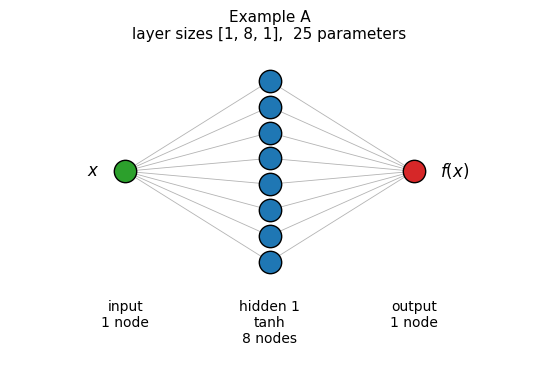

In [3]:
N = 8
draw_network([1, N, 1], activations=["tanh"], title="Example A", input_labels=["$x$"], output_labels=["$f(x)$"])
plt.show()

### 3.1 Way 1: `nn.Sequential`
`nn.Sequential(layer_1, layer_2, ...)` stores the layers in order. Calling the model applies them one after another to the input.
This is the shortest way to write a network whose computation is a plain chain of layers.

In [4]:
torch.manual_seed(0)
model_seq = nn.Sequential(
    nn.Linear(1, N),      # W^(1): shape (N, 1),  b^(1): shape (N,)
    nn.Tanh(),            # element-wise activation, no parameters
    nn.Linear(N, 1),      # W^(2): shape (1, N),  b^(2): shape (1,)
)
print(model_seq)

Sequential(
  (0): Linear(in_features=1, out_features=8, bias=True)
  (1): Tanh()
  (2): Linear(in_features=8, out_features=1, bias=True)
)


The layers are numbered `0, 1, 2` in the order given. The parameters carry the number of their layer in their name:

In [5]:
for name, p in model_seq.named_parameters():
    print(f"{name:10s} shape {tuple(p.shape)}")
n_params = sum(p.numel() for p in model_seq.parameters())
print("total number of parameters:", n_params, "  (formula: 3N + 1 =", 3 * N + 1, ")")
print("first layer:", model_seq[0])          # layers can be accessed by index

0.weight   shape (8, 1)
0.bias     shape (8,)
2.weight   shape (1, 8)
2.bias     shape (1,)
total number of parameters: 25   (formula: 3N + 1 = 25 )
first layer: Linear(in_features=1, out_features=8, bias=True)


### 3.2 Way 2: a class derived from `nn.Module`
The same network as a class. In `__init__` the layers are created and stored as attributes (this registers their parameters);
`forward` describes the computation.

In [6]:
class OneHiddenLayer(nn.Module):
    """f(x) = W2 tanh(W1 x + b1) + b2  with N hidden nodes."""

    def __init__(self, n_hidden):
        super().__init__()                        # set up the internal bookkeeping of nn.Module
        self.hidden = nn.Linear(1, n_hidden)      # first layer: 1 -> n_hidden
        self.activation = nn.Tanh()
        self.output = nn.Linear(n_hidden, 1)      # second layer: n_hidden -> 1

    def forward(self, x):
        h = self.activation(self.hidden(x))       # hidden layer: shape (B, n_hidden)
        return self.output(h)                     # output: shape (B, 1)

torch.manual_seed(0)
model_cls = OneHiddenLayer(N)
print(model_cls)
for name, p in model_cls.named_parameters():
    print(f"{name:15s} shape {tuple(p.shape)}")

OneHiddenLayer(
  (hidden): Linear(in_features=1, out_features=8, bias=True)
  (activation): Tanh()
  (output): Linear(in_features=8, out_features=1, bias=True)
)
hidden.weight   shape (8, 1)
hidden.bias     shape (8,)
output.weight   shape (1, 8)
output.bias     shape (1,)


The parameter names now come from the attribute names (`hidden.weight`, ...) instead of layer numbers; the shapes are the same.

### 3.3 Both ways give the same function
The two models were initialised with the same random seed, and the layers were created in the same order, so they even start with the same
random numbers. To make the comparison independent of this, we copy the parameters of `model_seq` into `model_cls` explicitly and compare the outputs.

`a.copy_(b)` writes the values of `b` into the existing tensor `a` (the trailing underscore marks a method that changes the tensor in place).
An assignment `model_cls.hidden.weight = model_seq[0].weight` would not copy anything: both models would then share one and the same tensor,
and training one of them would change the other.

In [7]:
with torch.no_grad():                                   # copying values is not part of any gradient computation
    model_cls.hidden.weight.copy_(model_seq[0].weight)
    model_cls.hidden.bias.copy_(model_seq[0].bias)
    model_cls.output.weight.copy_(model_seq[2].weight)
    model_cls.output.bias.copy_(model_seq[2].bias)

x = torch.linspace(-3, 3, 200).reshape(-1, 1)           # a batch of 200 inputs, shape (200, 1)
with torch.no_grad():
    y_seq, y_cls = model_seq(x), model_cls(x)
print("input shape :", tuple(x.shape), "  output shape:", tuple(y_seq.shape))
print("max |difference| between the two models:", (y_seq - y_cls).abs().max().item())

input shape : (200, 1)   output shape: (200, 1)
max |difference| between the two models: 0.0


### 3.4 The forward pass by hand
To see that there is nothing hidden in the model, we repeat the computation with the stored matrices, following the formula of Section 1.
The argument of the activation, $W^{(1)}_i x + b^{(1)}_i$, is called the **pre-activation** of node $i$.
In the left panel, `ax.plot(x, h)` receives an array `h` with $N$ columns; matplotlib then draws one curve per column, i.e. one curve per hidden node.

shapes: (200, 8) (200, 8) (200, 1)
max |model - by hand|: 1.1920928955078125e-07  (rounding of float32 numbers, about 1e-7)


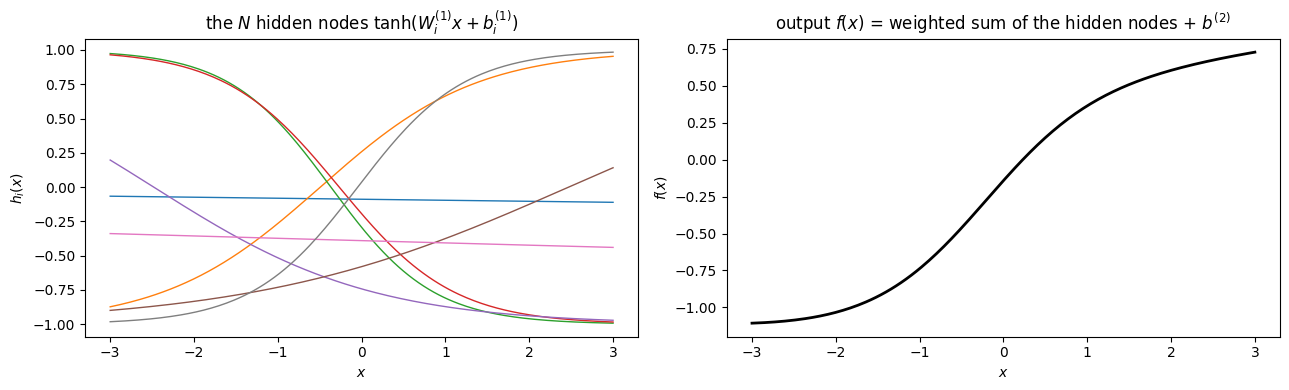

In [8]:
W1, b1 = model_seq[0].weight, model_seq[0].bias        # shapes (N, 1) and (N,)
W2, b2 = model_seq[2].weight, model_seq[2].bias        # shapes (1, N) and (1,)
with torch.no_grad():
    pre_activation = x @ W1.T + b1                      # (200, 1) @ (1, N) + (N,)  ->  (200, N)
    h = torch.tanh(pre_activation)                      # (200, N): the N hidden nodes for every input
    y_hand = h @ W2.T + b2                              # (200, N) @ (N, 1) + (1,)  ->  (200, 1)
print("shapes:", tuple(pre_activation.shape), tuple(h.shape), tuple(y_hand.shape))
print("max |model - by hand|:", (y_seq - y_hand).abs().max().item(), " (rounding of float32 numbers, about 1e-7)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(x, h, lw=1)
axes[0].set_title(r"the $N$ hidden nodes $\tanh(W^{(1)}_i x + b^{(1)}_i)$"); axes[0].set_xlabel("$x$"); axes[0].set_ylabel("$h_i(x)$")
axes[1].plot(x, y_seq, "k", lw=2)
axes[1].set_title("output $f(x)$ = weighted sum of the hidden nodes + $b^{(2)}$"); axes[1].set_xlabel("$x$"); axes[1].set_ylabel("$f(x)$")
fig.tight_layout(); plt.show()

Each curve on the left is a smoothed step $\tanh(W_i x + b_i)$ centred at $x = -b_i/W_i$; $|W_i|$ sets its steepness and the sign of $W_i$ its direction.
The initial weights are small ($|W_i| \le 1$), so the steps are gentle, and a node with $W_i$ close to zero is almost constant (two such nodes appear here).
The output on the right is the sum of these curves with the weights $W^{(2)}_i$, plus $b^{(2)}$. Training will move the centres, steepnesses and weights.

### 3.5 Way 3: explicit parameters and `einsum`
A third style writes the parameters as `nn.Parameter` tensors and the forward pass as index formulas with `torch.einsum`.
For a batch $x_{b}$ the layer formulas read $h_{bj} = \tanh\big(\sum_i x_{bi} W^{(1)}_{ji} + b^{(1)}_j\big)$ and $f_{bk} = \sum_j h_{bj}W^{(2)}_{kj} + b^{(2)}_k$, which
`einsum` takes literally: `"bi,ji->bj"` (sum over $i$, keep the batch index $b$).

This is still a class derived from `nn.Module`; what changes is that nothing is hidden in `nn.Linear`. The price is that the initialisation must be written by hand:
below, PyTorch's default for `nn.Linear` is reproduced (uniform in $[-1/\sqrt{n_{\rm in}}, 1/\sqrt{n_{\rm in}}]$ for weights and biases).
The factor $1/\sqrt{n_{\rm in}}$ keeps the sum $\sum_i W_{ji} h_i$ over the $n_{\rm in}$ inputs of a layer of order one whatever the width of the layer,
so that the $\tanh$ nodes start neither saturated nor all near zero.

Two functions appear here for the first time. `torch.empty(n, m)` reserves memory for a tensor of shape `(n, m)` without setting its values (the entries
are whatever was in memory). `.uniform_(a, b)` then overwrites the entries, in place, with random numbers distributed uniformly in $[a, b]$.

In [9]:
class OneHiddenLayerEinsum(nn.Module):
    # f(x) = W2 tanh(W1 x + b1) + b2, written with explicit parameters and einsum

    def __init__(self, n_hidden, n_in=1, n_out=1):
        super().__init__()
        bound1, bound2 = 1 / n_in**0.5, 1 / n_hidden**0.5
        # nn.Parameter registers a tensor as trainable; uniform_(a, b) fills it with uniform random numbers
        self.W1 = nn.Parameter(torch.empty(n_hidden, n_in).uniform_(-bound1, bound1))     # (N, n_in), as in nn.Linear
        self.b1 = nn.Parameter(torch.empty(n_hidden).uniform_(-bound1, bound1))           # (N,)
        self.W2 = nn.Parameter(torch.empty(n_out, n_hidden).uniform_(-bound2, bound2))    # (n_out, N)
        self.b2 = nn.Parameter(torch.empty(n_out).uniform_(-bound2, bound2))              # (n_out,)

    def forward(self, x):                                   # x: (B, n_in)
        h = torch.tanh(torch.einsum("bi,ji->bj", x, self.W1) + self.b1)    # h_bj = tanh(sum_i x_bi W1_ji + b1_j)
        return torch.einsum("bj,kj->bk", h, self.W2) + self.b2             # f_bk = sum_j h_bj W2_kj + b2_k

model_ein = OneHiddenLayerEinsum(N)
print("parameters:", [(name, tuple(p.shape)) for name, p in model_ein.named_parameters()])

with torch.no_grad():                                       # copy the parameters of the Sequential model
    model_ein.W1.copy_(model_seq[0].weight); model_ein.b1.copy_(model_seq[0].bias)
    model_ein.W2.copy_(model_seq[2].weight); model_ein.b2.copy_(model_seq[2].bias)
    print("max |Sequential - einsum model|:", (model_seq(x) - model_ein(x)).abs().max().item())

parameters: [('W1', (8, 1)), ('b1', (8,)), ('W2', (1, 8)), ('b2', (1,))]
max |Sequential - einsum model|: 1.1920928955078125e-07


All three ways give the same function. Way 3 is useful for teaching (the code is the formula), for operations that are not a plain matrix product
(contractions over several axes, e.g. in attention layers of transformers or in tensor-network models used in physics), and for layers with unusual parameter
shapes. For ordinary dense layers `nn.Linear` is preferable: it is equally fast (for such products `einsum` calls the same matrix-multiplication routine),
shorter, and its initialisation is handled by PyTorch.

The network is untrained: its parameters are random, so $f(x)$ is a random smooth function. Training (Section 10) changes the parameters
so that $f$ approximates data.

**Which way to choose?** All kinds of models are used in exactly the same way afterwards: `model(x)`, `model.parameters()`, training.
The choice depends only on how the data flow through the model; Section 8.3 discusses it in detail.

<hr/>
## 4. Example B: two hidden layers

Layer sizes $[1, 16, 16, 1]$ with $\tanh$ in both hidden layers:
$$\mathbf h^{(1)} = \tanh(\mathbf W^{(1)}x + \mathbf b^{(1)}),\quad \mathbf h^{(2)} = \tanh(\mathbf W^{(2)}\mathbf h^{(1)} + \mathbf b^{(2)}),\quad f(x) = \mathbf W^{(3)}\mathbf h^{(2)} + b^{(3)} .$$

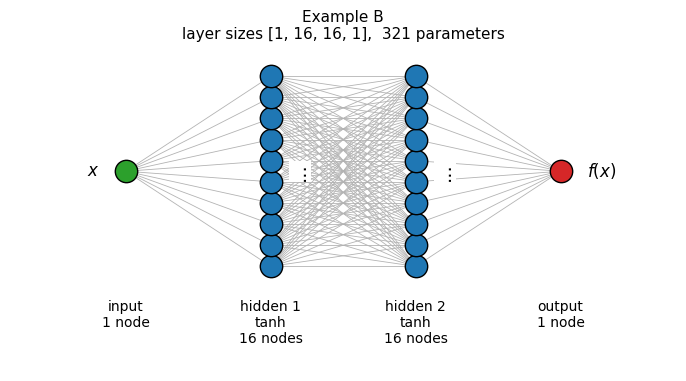

In [10]:
draw_network([1, 16, 16, 1], activations=["tanh", "tanh"], title="Example B", input_labels=["$x$"], output_labels=["$f(x)$"])
plt.show()

Both constructions of Example B, followed by a comparison of their parameter counts with the formula $\sum_l n_l(n_{l-1}+1)$:

In [11]:
# Way 1: nn.Sequential
model_B_seq = nn.Sequential(
    nn.Linear(1, 16), nn.Tanh(),       # hidden layer 1
    nn.Linear(16, 16), nn.Tanh(),      # hidden layer 2
    nn.Linear(16, 1),                  # output layer (no activation)
)

# Way 2: a class
class TwoHiddenLayers(nn.Module):
    def __init__(self, n1, n2):
        super().__init__()
        self.layer1 = nn.Linear(1, n1)
        self.layer2 = nn.Linear(n1, n2)
        self.layer3 = nn.Linear(n2, 1)

    def forward(self, x):
        h1 = torch.tanh(self.layer1(x))      # the activation can also be applied as a function
        h2 = torch.tanh(self.layer2(h1))
        return self.layer3(h2)

model_B_cls = TwoHiddenLayers(16, 16)

for model in [model_B_seq, model_B_cls]:
    # type(model) is the class of the object, and .__name__ its name as a string
    print(type(model).__name__, ": parameters =", sum(p.numel() for p in model.parameters()),
          "  formula:", 16 * (1 + 1) + 16 * (16 + 1) + 1 * (16 + 1))

Sequential : parameters = 321   formula: 321
TwoHiddenLayers : parameters = 321   formula: 321


Way 3 for Example B: the parameters of all layers are kept in a `nn.ParameterList`, and `forward` applies the same `einsum` formula to every layer.

The loop over the layers uses `zip(layer_sizes[:-1], layer_sizes[1:])`. For `layer_sizes = [1, 16, 16, 1]`, `layer_sizes[:-1]` is `[1, 16, 16]` (the last entry dropped)
and `layer_sizes[1:]` is `[16, 16, 1]` (the first entry dropped); `zip` pairs them into `(1, 16), (16, 16), (16, 1)`, the input and output sizes of every layer.
This idiom is used for all automatically built networks below.

In [12]:
class MLPEinsum(nn.Module):
    def __init__(self, layer_sizes):
        super().__init__()
        self.weights, self.biases = nn.ParameterList(), nn.ParameterList()   # lists that register their parameters
        for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
            bound = 1 / n_in**0.5
            self.weights.append(nn.Parameter(torch.empty(n_out, n_in).uniform_(-bound, bound)))
            self.biases.append(nn.Parameter(torch.empty(n_out).uniform_(-bound, bound)))

    def forward(self, h):
        n_layers = len(self.weights)
        for l, (W, b) in enumerate(zip(self.weights, self.biases)):
            h = torch.einsum("bi,ji->bj", h, W) + b          # the same formula for every layer
            if l < n_layers - 1:                              # no activation after the last layer
                h = torch.tanh(h)
        return h

model_B_ein = MLPEinsum([1, 16, 16, 1])
print("parameters:", sum(p.numel() for p in model_B_ein.parameters()), "(as for the other two ways: 321)")

parameters: 321 (as for the other two ways: 321)


In the class, the activation is applied with the function `torch.tanh` instead of a layer object `nn.Tanh()`: activations have no parameters,
so both forms are equivalent. The parameter count follows $n_1(n_0+1) + n_2(n_1+1) + n_3(n_2+1) = 32 + 272 + 17 = 321$.

<hr/>
## 5. Example C: several inputs and several outputs

Nothing changes in the construction except the sizes of the first and the last layer. A physics example: the input is a point $(x, y)$ in a plane,
the output three numbers, e.g. a potential $V$ and the two components of the force $(F_x, F_y)$. Layer sizes $[2, 32, 32, 3]$.
The input batch has shape `(B, 2)` (one row = one point), the output `(B, 3)`.

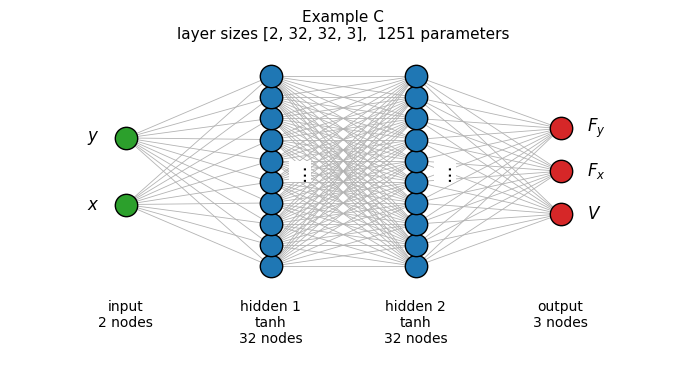

input shape : (5, 2)
output shape: (5, 3)  -> column 0: V, column 1: F_x, column 2: F_y


In [13]:
draw_network([2, 32, 32, 3], activations=["tanh", "tanh"], title="Example C",
             input_labels=["$x$", "$y$"], output_labels=["$V$", "$F_x$", "$F_y$"])
plt.show()

model_C = nn.Sequential(nn.Linear(2, 32), nn.Tanh(), nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 3))
points = torch.rand(5, 2)                        # a batch of 5 points (x, y)
print("input shape :", tuple(points.shape))
print("output shape:", tuple(model_C(points).shape), " -> column 0: V, column 1: F_x, column 2: F_y")

Five input points give five rows of three outputs. Only the first `Linear` layer (input size 2) and the last one (output size 3) differ from Example B.

<hr/>
## 6. Example D: a classifier for images

### 6.1 The task and the data
In Examples A–C the network returned a number (regression). Here it has to decide which of several categories an input belongs to (**classification**).
The categories are called **classes**. This word has nothing to do with Python classes: it is the standard name for the possible
answers of a classifier.

The data set is **MNIST**, the standard first example of image classification (lecture; Section 14 trains the network of this example on it): 70 000 grey-scale images of
handwritten digits, 60 000 for training and 10 000 for testing, each of $28\times28$ pixels and each labelled with the digit it shows. The classes are therefore the
ten digits $0, 1, \dots, 9$, and the **label** of an image is its class, an integer from 0 to 9.

The package `torchvision` (installed in Colab together with PyTorch) contains a loader for MNIST. `datasets.MNIST(root="data", train=False, download=True)`
downloads the data (about 12 MB, a few seconds) into a folder `data` the first time it is called and reads it from there afterwards; `train=False` selects the
10 000 test images, which are enough for looking at the data. The download prints a long progress bar; `contextlib.redirect_stdout` and `redirect_stderr`
send this text into an unused string buffer (`io.StringIO()`) instead of the screen.
If the download fails (for example without internet access), the `except` branch replaces the images by random numbers, so that the rest of the notebook still runs.

`.data` holds the images as one tensor of shape $(10000, 28, 28)$ with integer pixel values from 0 (background) to 255 (full ink intensity), and `.targets` the labels.
`torch.bincount(labels)` counts how often each value $0, 1, \dots, 9$ occurs.

In [14]:
import contextlib, io

try:
    from torchvision import datasets
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        mnist = datasets.MNIST(root="data", train=False, download=True)
    images_raw, labels = mnist.data, mnist.targets
    print("MNIST test set loaded")
except Exception as err:
    print("MNIST could not be loaded:", err)
    print("random images are used instead")
    images_raw = torch.randint(0, 256, (10000, 28, 28), dtype=torch.uint8)
    labels = torch.randint(0, 10, (10000,))

print("images:", tuple(images_raw.shape), images_raw.dtype,
      "  pixel values from", images_raw.min().item(), "to", images_raw.max().item())
print("labels:", tuple(labels.shape), "  first ten labels:", labels[:10].tolist())
print("number of images per class 0..9:", torch.bincount(labels).tolist())

MNIST test set loaded
images: (10000, 28, 28) torch.uint8   pixel values from 0 to 255
labels: (10000,)   first ten labels: [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]
number of images per class 0..9: [980, 1135, 1032, 1010, 982, 892, 958, 1028, 974, 1009]


The ten classes are about equally frequent (between about 890 and 1140 images each), so a classifier that guesses at random is right in about 10% of the cases.

Three examples of every class. `torch.nonzero(labels == k)` returns the positions of all images with label $k$ (as a column, hence `[:3, 0]` for the first three);
`imshow` draws a $28\times28$ array as an image, and the colour map `"gray_r"` (reversed grey) shows 0 as white and 255 as black, as on paper.

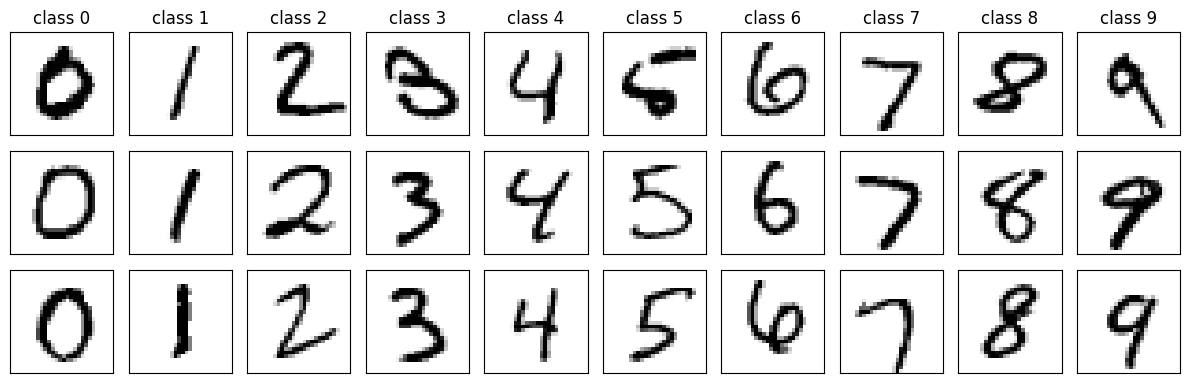

In [15]:
fig, axes = plt.subplots(3, 10, figsize=(12, 4))
for k in range(10):
    positions = torch.nonzero(labels == k)[:3, 0]       # first three images of class k
    for row in range(3):
        ax = axes[row, k]
        ax.imshow(images_raw[positions[row]], cmap="gray_r")
        ax.set_xticks([]); ax.set_yticks([])
        if row == 0:
            ax.set_title(f"class {k}")
fig.tight_layout(); plt.show()

The network does not see a picture but $28\times28 = 784$ numbers. The first test image with its pixel values written into the cells (only the non-zero ones;
all other pixels are 0):

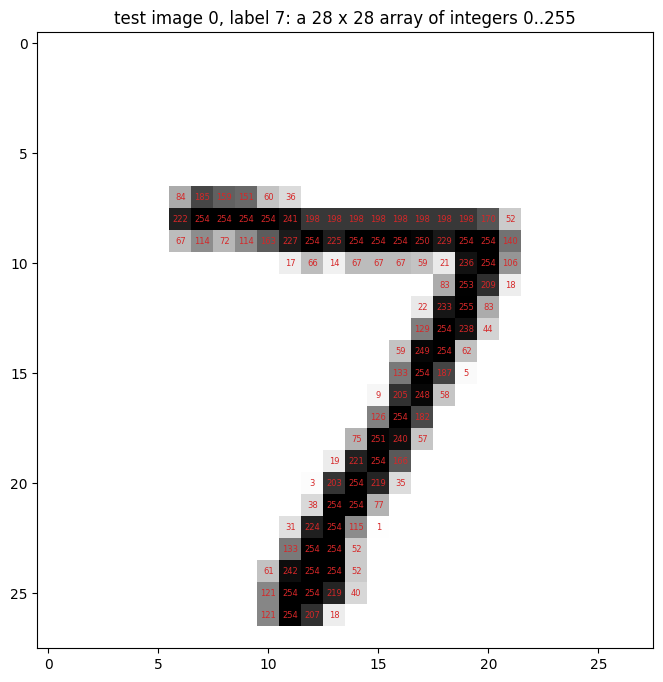

In [16]:
img = images_raw[0]
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img, cmap="gray_r")
for i in range(28):                          # row
    for j in range(28):                      # column
        if img[i, j] > 0:
            ax.text(j, i, str(img[i, j].item()), ha="center", va="center", fontsize=6, color="tab:red")
ax.set_title(f"test image 0, label {labels[0].item()}: a 28 x 28 array of integers 0..255")
plt.show()

### 6.2 The network
The network for these images, as in the lecture: a $28\times28$ image is flattened to a vector of $784$ pixel values,
two hidden layers with ReLU, and $10$ outputs, one per class. The outputs are arbitrary real numbers (*logits*); `softmax` turns them into
probabilities $q_k$, $k = 0, \dots, 9$, which are compared with the true label by the cross-entropy (lecture). The predicted class is
the one with the largest probability (`argmax`).
`nn.Flatten()` is a layer without parameters that reshapes `(B, 28, 28)` into `(B, 784)`.

The pixel values are divided by 255 and converted to floating-point numbers (`.float()`), so that the inputs lie in $[0, 1]$: inputs of order one
(the default initialisation of `nn.Linear` assumes inputs of order one; Section 10.1 explains what happens otherwise).

Two choices differ from Examples A–C:
- **ReLU instead of tanh.** $\mathrm{ReLU}(z) = \max(0, z)$ is cheap to compute and does not saturate for $z > 0$, which makes it the standard choice for
  classifiers and deep networks. A ReLU network is piecewise linear in its input. For regression of smooth physical functions (Examples A–C, Section 10)
  $\tanh$ is preferred, because the fitted function is then smooth and can be differentiated any number of times.
- **The widths 128 and 64.** They are illustrative; widths of order 10–1000 are all in use for this task. Decreasing widths ($784\to128\to64\to10$),
  which compress the input step by step, are a common convention but not a requirement. The same holds for the widths 8, 16 and 32 in Examples A–C.

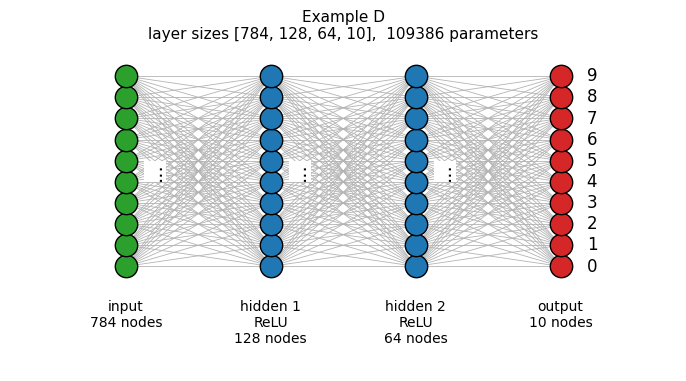

logits shape: (5, 10)   largest |logit|: 0.211
image 0: true class 7,  predicted 7,  probabilities [0.11 0.09 0.11 0.09 0.09 0.11 0.08 0.12 0.09 0.11]
image 1: true class 2,  predicted 7,  probabilities [0.11 0.09 0.1  0.09 0.09 0.11 0.09 0.12 0.09 0.12]
image 2: true class 1,  predicted 7,  probabilities [0.11 0.09 0.11 0.09 0.09 0.11 0.09 0.11 0.09 0.11]
image 3: true class 0,  predicted 7,  probabilities [0.11 0.09 0.1  0.09 0.1  0.11 0.09 0.12 0.09 0.11]
image 4: true class 4,  predicted 7,  probabilities [0.11 0.09 0.11 0.09 0.09 0.11 0.09 0.12 0.09 0.11]
sum of the probabilities of image 0: 0.9999999403953552
fraction of correctly classified test images: 0.105
how often each class 0..9 is predicted: [44, 0, 0, 0, 0, 4, 0, 9918, 0, 34]
parameters: 109386


In [17]:
draw_network([784, 128, 64, 10], activations=["ReLU", "ReLU"], title="Example D",
             output_labels=[f"{k}" for k in range(10)])
plt.show()

model_D = nn.Sequential(
    nn.Flatten(),                         # (B, 28, 28) -> (B, 784)
    nn.Linear(784, 128), nn.ReLU(),
    nn.Linear(128, 64), nn.ReLU(),
    nn.Linear(64, 10),                    # logits, one per class
)
images = images_raw.float() / 255         # integers 0..255 -> floats in [0, 1]
logits = model_D(images[:5])              # the first five test images
probs = torch.softmax(logits, dim=1)      # softmax over the class dimension
print("logits shape:", tuple(logits.shape), "  largest |logit|:", round(logits.abs().max().item(), 3))
# .detach() is needed before .numpy() because probs was computed with gradient tracking
for i in range(5):
    print(f"image {i}: true class {labels[i].item()},  predicted {probs[i].argmax().item()},  probabilities",
          probs[i].detach().numpy().round(2))
# float32 rounding: the sum differs from 1 by about 1e-7
print("sum of the probabilities of image 0:", probs[0].sum().item())

predicted = model_D(images).argmax(dim=1)                       # predicted class of all 10 000 test images
print(f"fraction of correctly classified test images: {(predicted == labels).float().mean().item():.3f}")
print("how often each class 0..9 is predicted:", torch.bincount(predicted, minlength=10).tolist())
print("parameters:", sum(p.numel() for p in model_D.parameters()))

The untrained classifier assigns roughly equal probabilities ($\approx 0.1$) to all ten classes. The largest of these nearly equal numbers, however, belongs
to the same class for almost every image (the line "how often each class 0..9 is predicted" printed above): the small differences between the ten logits come mostly from the random initial weights
and biases, which are the same for every input, and only a little from the image. The fraction of correct answers, about 10%, is therefore roughly the share of that one
class among the test images: no better than guessing.
The probabilities are all close to 1/10 because of the initialisation: the ten logits of the untrained network are small (the largest absolute value is printed above), and the softmax
$q_k = e^{z_k}/\sum_j e^{z_j}$ of ten nearly equal numbers is nearly $1/10$ each.
Training with the cross-entropy loss (Section 14) changes the $109\,386$ parameters so that the probability of the correct class approaches 1.
Almost all of these parameters belong to the first layer ($784\times128$ weights), as the summary in Section 9 shows.

<hr/>
## 7. Building networks automatically from a list of layer sizes

Writing every layer by hand is error-prone for deep networks. Since a dense network is determined by the list $[n_0, \dots, n_L]$ and the activation,
the layers can be created in a loop.

### 7.1 With `nn.Sequential`
`nn.Sequential(*layers)` accepts a Python list of layers; the star unpacks the list into separate arguments.

Sequential(
  (0): Linear(in_features=1, out_features=32, bias=True)
  (1): Tanh()
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): Tanh()
  (4): Linear(in_features=32, out_features=32, bias=True)
  (5): Tanh()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
parameters: 2209


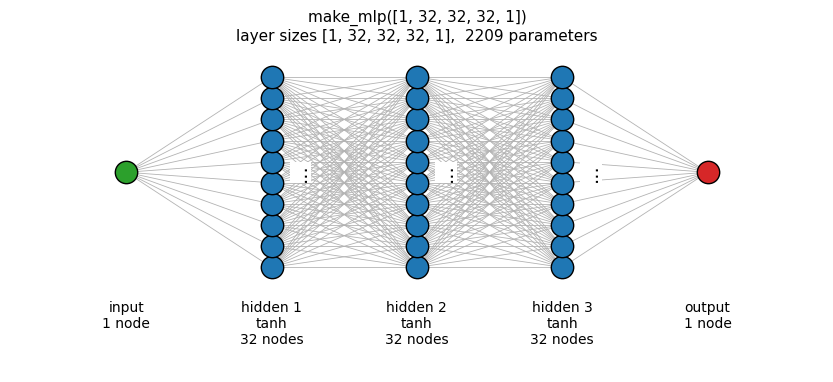

In [18]:
def make_mlp(layer_sizes, activation=nn.Tanh):
    """Dense network with the given layer sizes; `activation` (a class such as nn.Tanh) after every hidden layer."""
    layers = []
    for i in range(len(layer_sizes) - 1):
        n_in, n_out = layer_sizes[i], layer_sizes[i + 1]
        layers.append(nn.Linear(n_in, n_out))
        is_last_layer = (i == len(layer_sizes) - 2)
        if not is_last_layer:                     # no activation after the output layer
            layers.append(activation())           # a new activation object for every layer
    return nn.Sequential(*layers)

model_auto = make_mlp([1, 32, 32, 32, 1], activation=nn.Tanh)
print(model_auto)
print("parameters:", sum(p.numel() for p in model_auto.parameters()))
draw_network([1, 32, 32, 32, 1], activations=["tanh"] * 3, title="make_mlp([1, 32, 32, 32, 1])")
plt.show()

The same function produces the networks of Sections 3–5; Example D (Section 6) additionally needs `nn.Flatten()` in front and ReLU activations (`activation=nn.ReLU`). For instance `make_mlp([1, 8, 1])` is Example A and `make_mlp([2, 32, 32, 3])` is Example C.
Width and depth can now be varied with one argument:

In [19]:
for depth in [1, 2, 4, 8]:
    sizes = [1] + [32] * depth + [1]
    m = make_mlp(sizes)
    print(f"{depth} hidden layers of width 32: layer sizes {sizes}, parameters = {sum(p.numel() for p in m.parameters())}")

1 hidden layers of width 32: layer sizes [1, 32, 1], parameters = 97
2 hidden layers of width 32: layer sizes [1, 32, 32, 1], parameters = 1153
4 hidden layers of width 32: layer sizes [1, 32, 32, 32, 32, 1], parameters = 3265
8 hidden layers of width 32: layer sizes [1, 32, 32, 32, 32, 32, 32, 32, 32, 1], parameters = 7489


Every additional hidden layer of width 32 adds $32\times(32+1) = 1056$ parameters.

### 7.2 With a class and `nn.ModuleList`
In a class, a variable number of layers is stored in an `nn.ModuleList`, a list that registers the parameters of its elements. The loop over the
layers is then written in `forward`. This form is useful when `forward` has to do something between the layers (Section 8).

The argument `activation` has a different form in the two constructions. `make_mlp` receives a **class** (`nn.Tanh`) and creates a new layer object `activation()` for every
position in the chain, because `nn.Sequential` accepts only layer objects. In `forward` of the class below any function can be called directly, so the
**function** `torch.tanh` is passed.

In [20]:
class MLP(nn.Module):
    def __init__(self, layer_sizes, activation=torch.tanh):
        super().__init__()
        self.layers = nn.ModuleList(
            [nn.Linear(n_in, n_out) for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:])]
        )
        self.activation = activation

    def forward(self, x):
        for layer in self.layers[:-1]:            # all layers except the last one
            x = self.activation(layer(x))
        return self.layers[-1](x)                 # last layer without activation

model_list = MLP([1, 32, 32, 32, 1])
print("parameters:", sum(p.numel() for p in model_list.parameters()))
print("number of Linear layers:", len(model_list.layers))

parameters: 2209
number of Linear layers: 4


### 7.3 A common mistake: a plain Python list
If the layers are kept in an ordinary Python list, `nn.Module` does not see them: their parameters are not registered, `model.parameters()` does not
contain them, and an optimiser would never change them. No error is raised.

In [21]:
class BrokenMLP(nn.Module):
    def __init__(self, layer_sizes):
        super().__init__()
        self.layers = [nn.Linear(a, b) for a, b in zip(layer_sizes[:-1], layer_sizes[1:])]   # plain list: WRONG

    def forward(self, x):
        for layer in self.layers[:-1]:
            x = torch.tanh(layer(x))
        return self.layers[-1](x)

broken = BrokenMLP([1, 32, 32, 1])
print("output shape:", tuple(broken(torch.zeros(3, 1)).shape), "  <- forward works")
print("registered parameters:", sum(p.numel() for p in broken.parameters()), "  <- but there are none")

output shape: (3, 1)   <- forward works
registered parameters: 0   <- but there are none


<hr/>
## 8. Architectures beyond `nn.Sequential`

### 8.1 A skip (residual) connection
In a *residual* layer the input is added to the output: $\mathbf h \mapsto \mathbf h + \tanh(\mathbf W\mathbf h + \mathbf b)$.
Such connections make very deep networks trainable (ResNets). The addition of the input cannot be expressed as a chain of layers, so a class is needed.

In [22]:
class ResidualMLP(nn.Module):
    """input layer -> n_blocks residual blocks of width `width` -> output layer."""

    def __init__(self, n_in, width, n_blocks, n_out):
        super().__init__()
        self.input_layer = nn.Linear(n_in, width)
        self.blocks = nn.ModuleList([nn.Linear(width, width) for _ in range(n_blocks)])
        self.output_layer = nn.Linear(width, n_out)

    def forward(self, x):
        h = torch.tanh(self.input_layer(x))
        for block in self.blocks:
            h = h + torch.tanh(block(h))          # skip connection: the input of the block is added to its output
        return self.output_layer(h)

res = ResidualMLP(n_in=1, width=16, n_blocks=4, n_out=1)
print("output shape:", tuple(res(torch.zeros(5, 1)).shape), "  parameters:", sum(p.numel() for p in res.parameters()))

output shape: (5, 1)   parameters: 1137


### 8.2 A physics constraint built into the network
A wavefunction of a particle in a box $[0, 1]$ must vanish at $x = 0$ and $x = 1$. An unconstrained network $\mathrm{NN}(x)$ does not satisfy this,
but the ansatz
$$\psi(x) = x\,(1-x)\,\mathrm{NN}(x)$$
does, for **every** value of the parameters. The boundary conditions are then never violated during training. The network inside can be any
model, e.g. one made with `make_mlp`.

In [23]:
class BoxWavefunction(nn.Module):
    """psi(x) = x (1 - x) NN(x): vanishes at x = 0 and x = 1 for any parameters of NN."""

    def __init__(self, layer_sizes):
        super().__init__()
        self.net = make_mlp(layer_sizes)          # a network inside a network: its parameters are registered as well

    def forward(self, x):
        return x * (1 - x) * self.net(x)

psi = BoxWavefunction([1, 16, 16, 1])
x_box = torch.linspace(0, 1, 101).reshape(-1, 1)
with torch.no_grad():
    values = psi(x_box)
print("psi(0) =", values[0].item(), "  psi(1) =", values[-1].item())
print("parameters:", sum(p.numel() for p in psi.parameters()), "(all inside psi.net)")

psi(0) = -0.0   psi(1) = -0.0
parameters: 321 (all inside psi.net)


Both boundary values are zero. The printed sign of $-0.0$ is an artefact of floating-point numbers, which have a signed zero: $0$ multiplied by a negative
number gives $-0.0$, which equals $0.0$ in every comparison.

### 8.3 When to use `nn.Sequential` and when a class

**The rule.** `nn.Sequential` describes exactly one kind of computation: **one** input tensor passes through a **fixed chain** of layers, and the output of each
layer is the input of the next one. Whenever the computation can be drawn as such a chain, `nn.Sequential` is the shortest and clearest choice.
For everything else a class with a `forward` method is needed, because `forward` can contain arbitrary Python code.

| situation | `nn.Sequential` | class |
|---|---|---|
| chain of layers, one input, one output | yes | yes (longer) |
| a layer is skipped or its input is added to its output (skip connection, 8.1) | no | yes |
| a fixed formula around the network, e.g. a physical constraint (8.2) | no | yes |
| the same layer (same weights) is used several times, e.g. to enforce a symmetry | no | yes |
| several inputs (e.g. a position and a parameter) or several outputs treated differently | no | yes |
| intermediate results are needed (e.g. for analysis) | only by looping over the layers by hand | yes, returned by `forward` |
| a trainable number that is not part of any layer (`nn.Parameter`) | no | yes |
| `if` statements or loops in the computation | no | yes |

In practice the two are **combined**: the chain-like parts of a model are written as `nn.Sequential` blocks (or built with `make_mlp`), and a class connects them.
The following class shows several items of the table at once: an even wavefunction $\psi(x) = A\,[\,g(x) + g(-x)\,]$, where the same network $g$ is applied
twice (shared weights enforce $\psi(-x) = \psi(x)$), $A$ is a trainable number outside any layer, and `forward` can also return the intermediate values $g(\pm x)$.

In [24]:
class EvenFunction(nn.Module):
    # psi(x) = A * (g(x) + g(-x)): even in x for any parameters of g and any A

    def __init__(self, layer_sizes):
        super().__init__()
        self.g = make_mlp(layer_sizes)                 # a Sequential block inside the class
        self.amplitude = nn.Parameter(torch.ones(1))   # a trainable number that is not part of any layer;
                                                       # it starts at 1 (any non-zero value works, it is trained)

    def forward(self, x, return_parts=False):
        g_plus = self.g(x)                             # the same network (same weights) ...
        g_minus = self.g(-x)                           # ... applied a second time
        psi = self.amplitude * (g_plus + g_minus)
        if return_parts:                               # ordinary Python control flow
            return psi, g_plus, g_minus
        return psi

even = EvenFunction([1, 16, 16, 1])
x_sym = torch.linspace(-2, 2, 9).reshape(-1, 1)
with torch.no_grad():
    psi_vals, gp, gm = even(x_sym, return_parts=True)
print("psi(x)  :", psi_vals.squeeze().numpy().round(4))
print("psi(-x) :", psi_vals.flip(0).squeeze().numpy().round(4), "  <- identical: the symmetry holds exactly")
print("parameters:", [name for name, _ in even.named_parameters()][:3], "...")
print("number of parameters:", sum(p.numel() for p in even.parameters()), "= parameters of g + 1 (the amplitude)")

psi(x)  : [-0.2476 -0.2854 -0.3438 -0.4036 -0.4297 -0.4036 -0.3438 -0.2854 -0.2476]
psi(-x) : [-0.2476 -0.2854 -0.3438 -0.4036 -0.4297 -0.4036 -0.3438 -0.2854 -0.2476]   <- identical: the symmetry holds exactly
parameters: ['amplitude', 'g.0.weight', 'g.0.bias'] ...
number of parameters: 322 = parameters of g + 1 (the amplitude)


`flip(0)` reverses the order of the rows; since the grid is symmetric around 0, it turns the values at $x$ into the values at $-x$.
The network $g$ appears once in the list of parameters although it is used twice: its weights are shared.

<hr/>
## 9. Inspecting a model

Three tools are used constantly:
- `named_parameters()` — names and tensors of all trainable parameters;
- `state_dict()` — a dictionary name $\to$ tensor with all parameters (used for saving, Section 12);
- passing a batch through the layers one by one and printing the shapes — the quickest way to find shape errors.

In [25]:
def summary(model, x):
    """Print the output shape and the number of parameters of every layer of an nn.Sequential model for the input batch x."""
    print(f"{'layer':35s} {'output shape':15s} parameters")
    print(f"{'input':35s} {str(tuple(x.shape)):15s}")
    total = 0
    for layer in model:                             # an nn.Sequential can be iterated over
        x = layer(x)
        n = sum(p.numel() for p in layer.parameters())
        total += n
        print(f"{str(layer):35s} {str(tuple(x.shape)):15s} {n}")
    print(f"total parameters: {total}")

summary(model_D, images[:4])                    # four MNIST test images (Section 6)

layer                               output shape    parameters
input                               (4, 28, 28)    
Flatten(start_dim=1, end_dim=-1)    (4, 784)        0
Linear(in_features=784, out_features=128, bias=True) (4, 128)        100480
ReLU()                              (4, 128)        0
Linear(in_features=128, out_features=64, bias=True) (4, 64)         8256
ReLU()                              (4, 64)         0
Linear(in_features=64, out_features=10, bias=True) (4, 10)         650
total parameters: 109386


The shapes change only in the `Flatten` and `Linear` layers; activations keep the shape. The first `Linear` layer holds 92% of all parameters.

The `state_dict` of Example A: the same four parameter tensors as `named_parameters()`, stored in a dictionary name $\to$ tensor.

In [26]:
sd = model_seq.state_dict()
for key, value in sd.items():
    print(f"{key:10s} {tuple(value.shape)}")

0.weight   (8, 1)
0.bias     (8,)
2.weight   (1, 8)
2.bias     (1,)


<hr/>
## 10. The training loop in detail

### 10.1 Data
We simulate a measurement of a damped oscillation, $y(t) = e^{-0.2t}\cos(2t)$, at $K = 200$ random times $t\in[0, 10]$ with Gaussian noise of
standard deviation $0.05$. The data are split at random into three parts with different roles:
- the **training set** (120 points) is used to change the parameters;
- the **validation set** (40 points) is used to monitor training and to make choices (architecture, learning rate, number of epochs); the parameters
  never see it, but our decisions do;
- the **test set** (40 points) is used **once, at the very end**, to estimate how well the final model works on new data. Because no decision was based
  on it, this estimate is not biased by our choices.

The fractions 60 / 20 / 20 % are a convention; splits between about 60–80 % for training and 10–20 % each for validation and test are common.
The exact values are not critical, but the validation and test sets must contain enough points for their mean losses to be meaningful averages.
The noise level $0.05$ is also arbitrary: small compared with the amplitude 1 of the signal, but large enough to be visible in the plot.

Two practical details:
- PyTorch layers expect inputs of shape `(B, n_in)`, here `(B, 1)`; targets must have the same shape as the outputs, `(B, 1)`.
- The input $t\in[0, 10]$ is **rescaled** to $[-1, 1]$. With one input, the default initialisation of `nn.Linear` draws the first-layer weights and biases
  uniformly from $[-1, 1]$ (the bound is $1/\sqrt{n_{\rm in}} = 1$), so the pre-activations $W t + b$ are of order $|t|$. For $t\sim10$ most of them lie far in the
  flat part of $\tanh$ ($\tanh 3 \approx 0.995$): these nodes start saturated, their gradients are small, and training slows down (Section 13.4 shows the effect).

Two new operations appear in the code. `torch.randperm(K)` returns the integers $0, \dots, K-1$ in random order; the first 120 of them become the training indices,
and so on. It receives its own random-number generator `torch.Generator().manual_seed(0)`, so that the split is reproducible and does not depend on how many
random numbers were drawn earlier in the notebook. `X_all[train_idx]`, indexing with a tensor of integers, selects the rows with these indices in this order;
since inputs and targets are indexed with the same indices, every input stays paired with its target.

training set  : (120, 1) (120, 1)
validation set: (40, 1) (40, 1)
test set      : (40, 1) (40, 1)  <- not used until Section 12


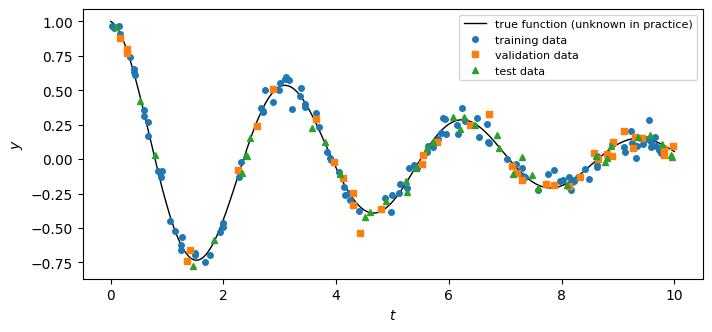

In [27]:
def damped_oscillation(t):
    return np.exp(-0.2 * t) * np.cos(2 * t)

rng = np.random.default_rng(0)
K = 200
t_data = rng.uniform(0, 10, K)
y_data = damped_oscillation(t_data) + 0.05 * rng.normal(size=K)

def scale(t):
    """Map t in [0, 10] to [-1, 1]."""
    return t / 5.0 - 1.0

# tensors of shape (K, 1); float32 is the PyTorch default and matches the model parameters
X_all = torch.tensor(scale(t_data), dtype=torch.float32).reshape(-1, 1)
Y_all = torch.tensor(y_data, dtype=torch.float32).reshape(-1, 1)

perm = torch.randperm(K, generator=torch.Generator().manual_seed(0))   # random order of the indices 0..K-1
train_idx, val_idx, test_idx = perm[:120], perm[120:160], perm[160:]   # 120 / 40 / 40 points
X_train, Y_train = X_all[train_idx], Y_all[train_idx]
X_val, Y_val = X_all[val_idx], Y_all[val_idx]
X_test, Y_test = X_all[test_idx], Y_all[test_idx]
print("training set  :", tuple(X_train.shape), tuple(Y_train.shape))
print("validation set:", tuple(X_val.shape), tuple(Y_val.shape))
print("test set      :", tuple(X_test.shape), tuple(Y_test.shape), " <- not used until Section 12")

t_plot = np.linspace(0, 10, 500)
X_plot = torch.tensor(scale(t_plot), dtype=torch.float32).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t_plot, damped_oscillation(t_plot), "k", lw=1, label="true function (unknown in practice)")
# t_data is a NumPy array, so it is indexed with the NumPy version of the index tensor
ax.plot(t_data[train_idx.numpy()], Y_train, "o", ms=4, label="training data")
ax.plot(t_data[val_idx.numpy()], Y_val, "s", ms=4, label="validation data")
ax.plot(t_data[test_idx.numpy()], Y_test, "^", ms=4, label="test data")
ax.set_xlabel("$t$"); ax.set_ylabel("$y$"); ax.legend(fontsize=8); plt.show()

### 10.2 Model, loss function, optimiser
- **model**: `make_mlp([1, 32, 32, 1])`;
- **loss function**: `nn.MSELoss()` computes $\frac1B\sum_i (f(x_i) - y_i)^2$ for a batch (equivalent to `torch.mean((pred - y)**2)`);
- **optimiser**: an object from `torch.optim` that holds references to the parameters and implements the update rule.

Two hidden layers of 32 nodes are a modest size for a one-dimensional function with about three periods of oscillation on the interval; Section 12 compares this choice
with smaller and larger networks. The learning rate 0.1 of SGD is arbitrary here: the next cell performs a single step only, to check the update rule,
and any value would serve. `torch.manual_seed(1)` immediately before the model is created fixes its initial parameters, so that the runs below start from
the same point and can be compared; the value of the seed is arbitrary.

In [28]:
torch.manual_seed(1)
model = make_mlp([1, 32, 32, 1])
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)     # plain gradient descent first, to check it by hand

### 10.3 One training step in slow motion
One step consists of five lines. We follow three of the parameters (the first three biases of the first layer) and their gradients through
the step, and check that `optimizer.step()` for SGD is exactly the update $\theta \leftarrow \theta - \eta\,\partial\mathcal L/\partial\theta$, where $\theta$ is any parameter, $\mathcal L$ the loss and $\eta$ the learning rate (`lr`).

In [29]:
p = model[0].bias                                   # a parameter tensor of shape (32,); we print its first 3 entries
print("before the step:     p[:3] =", p[:3].detach().numpy(), "  p.grad =", p.grad)

# 1) forward pass: predictions for the whole training set
pred = model(X_train)                               # shape (120, 1)
# 2) loss: a single number (a tensor with one element) that depends on all parameters
loss = loss_fn(pred, Y_train)
print("loss:", loss.item())
# 3) reset the gradients stored from a previous step (here there are none yet, but this line is always needed)
optimizer.zero_grad()
# 4) backward pass: compute d loss / d parameter for every parameter, stored in .grad
loss.backward()
print("after backward():    p.grad[:3] =", p.grad[:3].numpy())
p_old, grad_old = p.detach().clone(), p.grad.clone()  # copies, for the check below
# 5) update the parameters with the rule of the optimiser
optimizer.step()
print("after step():        p[:3] =", p[:3].detach().numpy())
print("p_old - lr * grad:         ", (p_old - 0.1 * grad_old)[:3].numpy())
print("max |difference|:", (p.detach() - (p_old - 0.1 * grad_old)).abs().max().item())

before the step:     p[:3] = [ 0.6600598 -0.9111377 -0.9508084]   p.grad = None
loss: 0.21944643557071686
after backward():    p.grad[:3] = [ 0.0114674  -0.01462021  0.01155732]
after step():        p[:3] = [ 0.6589131  -0.90967566 -0.95196414]
p_old - lr * grad:          [ 0.6589131  -0.90967566 -0.95196414]
max |difference|: 0.0


Before the first `backward()` no gradient has been computed, so `p.grad` is `None` rather than a tensor of zeros.
The copies `p_old, grad_old` are made with `clone()` because `optimizer.step()` changes `p` in place: without `clone()`, `p_old` would be a second name for the
same memory and would change together with `p`. `detach()` excludes the copy from the gradient computation.

The optimiser changed every parameter by $-\eta\times$ its gradient, as gradient descent prescribes. More advanced optimisers (momentum, Adam) use the
same `.grad` tensors but a different update rule.

### 10.4 The complete loop (full batch)
Repeating the five lines gives the training loop. In every iteration we also compute the validation loss, inside `torch.no_grad()` (no gradients are
needed for monitoring, which saves memory and time). We use Adam (an optimiser that adapts the step size of every parameter using running averages of its gradients; see the lecture), which converges faster here.

The learning rate $10^{-2}$ is a common starting value for Adam on small problems. In this example values between about $3\cdot10^{-3}$ and $3\cdot10^{-2}$
bring the training loss to the noise level within 2000 steps; with $10^{-3}$ the loss decreases more slowly and reaches the noise level only near the end of the 2000 steps, and with $10^{-1}$ the loss
fluctuates from step to step. With $10^{-2}$ the training loss is within a few per cent of its final value after about 1000 steps; the number of steps, 2000,
leaves a margin and is otherwise arbitrary.

In [30]:
torch.manual_seed(1)
model = make_mlp([1, 32, 32, 1])
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
n_steps = 2000
train_hist, val_hist = [], []

t0 = time.perf_counter()
for step in range(n_steps):
    pred = model(X_train)                         # 1) forward
    loss = loss_fn(pred, Y_train)                 # 2) loss
    optimizer.zero_grad()                         # 3) reset gradients
    loss.backward()                               # 4) backward
    optimizer.step()                              # 5) update

    with torch.no_grad():                         # monitoring only
        val_loss = loss_fn(model(X_val), Y_val)
    train_hist.append(loss.item())
    val_hist.append(val_loss.item())
print(f"{n_steps} steps in {time.perf_counter() - t0:.1f} s;  final training loss {train_hist[-1]:.2e}, validation loss {val_hist[-1]:.2e}")
print(f"noise variance 0.05^2 = {0.05**2:.1e}")

2000 steps in 1.2 s;  final training loss 2.67e-03, validation loss 4.64e-03
noise variance 0.05^2 = 2.5e-03


Left: training and validation loss versus the step (logarithmic scale). Right: the trained network on a dense grid of times, together with the training data
and the true function.

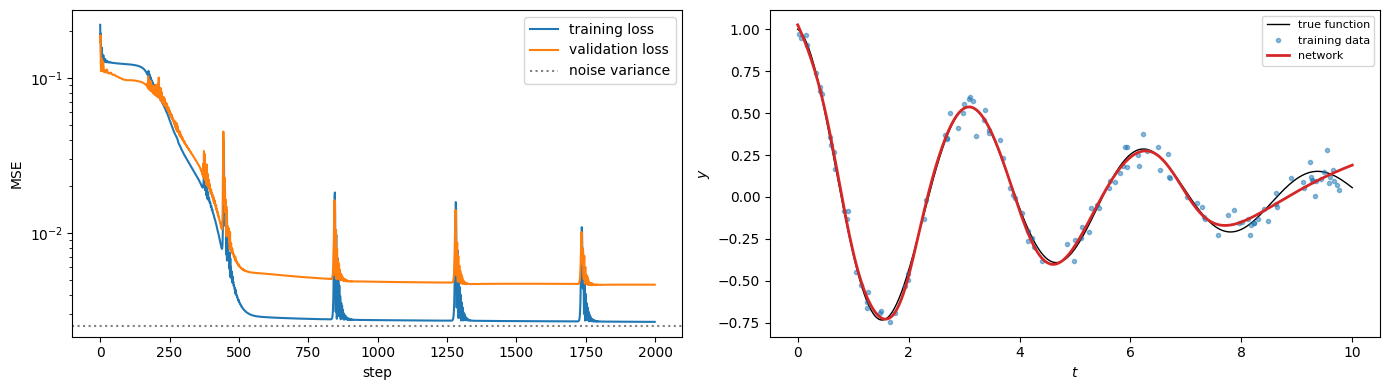

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].semilogy(train_hist, label="training loss"); axes[0].semilogy(val_hist, label="validation loss")
axes[0].axhline(0.05**2, color="gray", ls=":", label="noise variance")
axes[0].set_xlabel("step"); axes[0].set_ylabel("MSE"); axes[0].legend()
with torch.no_grad():
    y_fit = model(X_plot)
axes[1].plot(t_plot, damped_oscillation(t_plot), "k", lw=1, label="true function")
axes[1].plot(t_data[train_idx.numpy()], Y_train, "o", ms=3, alpha=0.5, label="training data")
axes[1].plot(t_plot, y_fit, "C3", lw=2, label="network")
axes[1].set_xlabel("$t$"); axes[1].set_ylabel("$y$"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

The training loss decreases to about the variance of the noise, $0.05^2 = 2.5\cdot10^{-3}$: the remaining error is the noise in the data, which no model can
predict. Indeed, if the network were exactly the true function $g$, then $f(t_i) - y_i = g(t_i) - (g(t_i) + \varepsilon_i) = -\varepsilon_i$, and the mean of
$\varepsilon_i^2$ over many points is the variance $\sigma^2 = 0.05^2$. A training loss far below $\sigma^2$ would mean that the network reproduces the noise itself. The validation loss is somewhat larger (printed above): with only 120 training points the network also fits part of the noise of these particular points,
which does not carry over to new points. The difference between training and validation loss measures this effect; it becomes large when a network *overfits*.
<hr/>
## 11. Mini-batches, epochs and validation

### 11.1 Mini-batches
For large data sets the full-batch loss is too expensive to compute in every step. The training set is then split into **mini-batches**; every step uses
one mini-batch, and one pass over all mini-batches is an **epoch**. The gradient of a mini-batch is a noisy estimate of the full gradient
(this is *stochastic* gradient descent). PyTorch provides two helpers:
- `TensorDataset(X, Y)` pairs inputs with targets;
- `DataLoader(dataset, batch_size=..., shuffle=True)` returns the mini-batches of one epoch, in a new random order every epoch.

The batch size is a free choice; powers of two between 16 and 256 are customary. Smaller batches give noisier gradients and more updates per epoch, larger
batches the opposite. Here 32 is chosen so that an epoch of 120 samples consists of a few (four) steps.

In [32]:
from torch.utils.data import TensorDataset, DataLoader

train_set = TensorDataset(X_train, Y_train)
loader = DataLoader(train_set, batch_size=32, shuffle=True)

print("number of training samples:", len(train_set))
print("mini-batches per epoch    :", len(loader), " (= 120 / 32 rounded up; the last batch has 24 samples)")
for i, (xb, yb) in enumerate(loader):              # one epoch
    print(f"  batch {i}: inputs {tuple(xb.shape)}, targets {tuple(yb.shape)}")

number of training samples: 120
mini-batches per epoch    : 4  (= 120 / 32 rounded up; the last batch has 24 samples)
  batch 0: inputs (32, 1), targets (32, 1)
  batch 1: inputs (32, 1), targets (32, 1)
  batch 2: inputs (32, 1), targets (32, 1)
  batch 3: inputs (24, 1), targets (24, 1)


### 11.2 The loop with mini-batches
The five lines are the same; they are now inside a loop over the mini-batches, which is inside a loop over the epochs.
The training loss of an epoch is the plain average of its mini-batch losses (`np.mean(batch_losses)`). It is collected while the parameters are still changing
and it gives the shorter last batch (24 samples) the same weight as the others, so it differs slightly from the loss of the final model on the full training set.

`model.train()` and `model.eval()` switch layers such as dropout and batch normalisation (introduced later in the course) between their training
and evaluation behaviour. Our model has no such layers, so the calls change nothing here, but they belong to the standard loop.

final training loss 2.83e-03, validation loss 4.65e-03


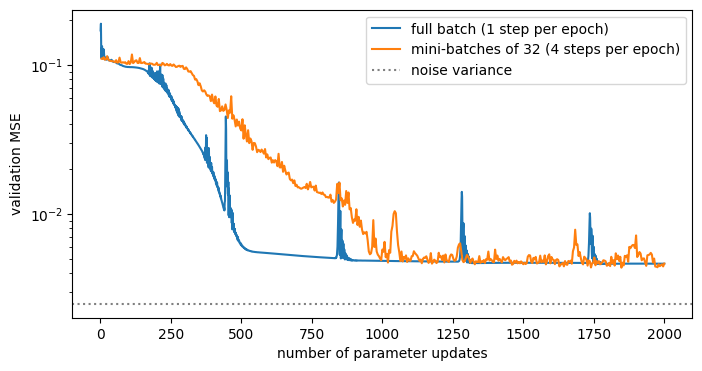

In [33]:
torch.manual_seed(1)
model_mb = make_mlp([1, 32, 32, 1])
optimizer = torch.optim.Adam(model_mb.parameters(), lr=1e-2)
n_epochs = 500                                     # 500 epochs x 4 batches = 2000 steps, as in Section 10.4
train_hist_mb, val_hist_mb = [], []

for epoch in range(n_epochs):
    model_mb.train()
    batch_losses = []
    for xb, yb in loader:
        loss = loss_fn(model_mb(xb), yb)           # forward + loss on one mini-batch
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())
    model_mb.eval()
    with torch.no_grad():
        val_hist_mb.append(loss_fn(model_mb(X_val), Y_val).item())
    train_hist_mb.append(np.mean(batch_losses))

print(f"final training loss {train_hist_mb[-1]:.2e}, validation loss {val_hist_mb[-1]:.2e}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(np.arange(1, n_steps + 1), val_hist, label="full batch (1 step per epoch)")
# epoch e of the mini-batch run ends after e * 4 updates: both curves are plotted against the number of updates
ax.semilogy(np.arange(1, n_epochs + 1) * len(loader), val_hist_mb, label="mini-batches of 32 (4 steps per epoch)")
ax.axhline(0.05**2, color="gray", ls=":", label="noise variance")
ax.set_xlabel("number of parameter updates"); ax.set_ylabel("validation MSE"); ax.legend()
plt.show()

Both runs perform 2000 parameter updates. The mini-batch curve is noisier, because every step uses a different random subset of the data.
For this small data set the full batch is cheap; for real data sets (millions of samples) only mini-batches are feasible.
<hr/>
## 12. A reusable training function; saving and loading a model

The loop of Section 11.2 is written once as a function and then used to compare architectures.

The four architectures span almost three orders of magnitude in the number of parameters (13 to 8513), from too small to more than enough; any similar
sequence shows the same trend. The default `n_epochs=300` (1200 updates) is smaller than the 2000 updates of Sections 10–11 to keep the comparison fast.

[1, 4, 1]            parameters     13   final validation MSE 9.86e-02


[1, 32, 1]           parameters     97   final validation MSE 9.25e-02


[1, 32, 32, 1]       parameters   1153   final validation MSE 4.95e-03


[1, 64, 64, 64, 1]   parameters   8513   final validation MSE 4.62e-03


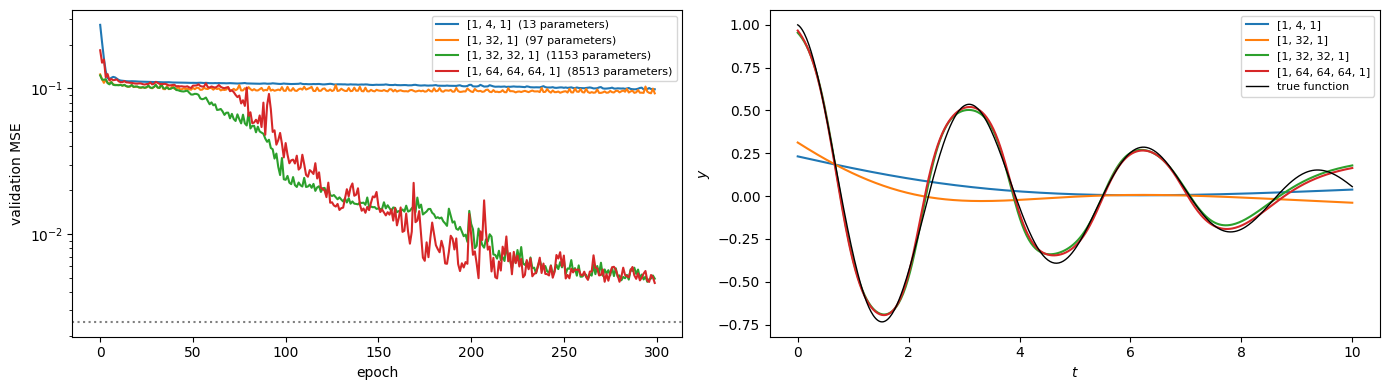

In [34]:
def train(model, X_train, Y_train, X_val, Y_val, n_epochs=300, batch_size=32, lr=1e-2, seed=0):
    """Train `model` with Adam and mini-batches; return the training and validation loss per epoch."""
    torch.manual_seed(seed)                                    # reproducible shuffling of the mini-batches
    loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = {"train": [], "val": []}
    for epoch in range(n_epochs):
        model.train()
        batch_losses = []
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            history["val"].append(loss_fn(model(X_val), Y_val).item())
        history["train"].append(np.mean(batch_losses))
    return history

architectures = [[1, 4, 1], [1, 32, 1], [1, 32, 32, 1], [1, 64, 64, 64, 1]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
trained = {}
for sizes in architectures:
    torch.manual_seed(0)
    m = make_mlp(sizes)
    hist = train(m, X_train, Y_train, X_val, Y_val)
    trained[str(sizes)] = m          # a list cannot be a dictionary key, so its text "[1, 4, 1]" is used
    n_par = sum(p.numel() for p in m.parameters())
    axes[0].semilogy(hist["val"], label=f"{sizes}  ({n_par} parameters)")
    with torch.no_grad():
        axes[1].plot(t_plot, m(X_plot), lw=1.5, label=str(sizes))
    print(f"{str(sizes):20s} parameters {n_par:6d}   final validation MSE {hist['val'][-1]:.2e}")
axes[0].axhline(0.05**2, color="gray", ls=":"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("validation MSE"); axes[0].legend(fontsize=8)
axes[1].plot(t_plot, damped_oscillation(t_plot), "k", lw=1, label="true function")
axes[1].set_xlabel("$t$"); axes[1].set_ylabel("$y$"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

The two one-hidden-layer networks are far from the noise level, although Section 3 introduced exactly this kind of network through the Universal Approximation
Theorem. The theorem guarantees that suitable parameters exist for a large enough $N$; it says nothing about whether a given optimiser finds them within a given
number of steps. Here the networks with one hidden layer converge much more slowly and are far from converged after 300 epochs: trained longer (measured separately, same seeds),
`[1, 32, 1]` reaches a validation MSE of about $9\cdot10^{-3}$ after 1000 epochs and $7\cdot10^{-3}$ after 3000, while `[1, 32, 32, 1]` is at about
$4\cdot10^{-3}$ already after 1000 epochs. With a fixed training budget the deeper networks reach a good fit much faster.

**Choosing a model and testing it.** The architecture is chosen by the **validation** loss. Only for the chosen model is the **test** loss computed,
once; it estimates the error on new data. (Choosing by the test loss would make the test set a second validation set, and the estimate would be too optimistic.)

In [35]:
val_final = {}
for name, m in trained.items():
    m.eval()
    with torch.no_grad():
        val_final[name] = loss_fn(m(X_val), Y_val).item()
# min over a dictionary runs over its keys; key=val_final.get compares the keys by their values val_final[name],
# so the result is the name of the architecture with the smallest validation loss
best_name = min(val_final, key=val_final.get)
best = trained[best_name]
with torch.no_grad():
    test_loss = loss_fn(best(X_test), Y_test).item()
print("validation MSE per architecture:", {k: f"{v:.2e}" for k, v in val_final.items()})   # dictionary comprehension, for formatting only
print(f"chosen: {best_name};  test MSE = {test_loss:.2e}  (noise variance {0.05**2:.1e})")

validation MSE per architecture: {'[1, 4, 1]': '9.86e-02', '[1, 32, 1]': '9.25e-02', '[1, 32, 32, 1]': '4.95e-03', '[1, 64, 64, 64, 1]': '4.62e-03'}
chosen: [1, 64, 64, 64, 1];  test MSE = 5.30e-03  (noise variance 2.5e-03)


The two largest networks have nearly equal validation losses. The difference is smaller than the spread caused by the random initialisation alone: repeated with
the seeds 0–4, the final validation MSE varies between $4.5\cdot10^{-3}$ and $6.1\cdot10^{-3}$ for `[1, 32, 32, 1]` and between $4.0\cdot10^{-3}$ and
$8.4\cdot10^{-3}$ for `[1, 64, 64, 64, 1]`. The smaller network would therefore be an equally good and cheaper choice; the rule "smallest validation loss" applied
to a single run is a simplification.

**Saving and loading.** A trained model is saved as its `state_dict` (the parameter tensors). To load it, a model with the **same architecture** is created
and the stored tensors are copied into it.

`torch.save(obj, filename)` writes a Python object containing tensors to a file (the extension `.pt` is a convention), and `torch.load(filename)` reads it back.
The `state_dict` contains only names and numbers, so the file does not depend on the Python code of the model; that code (here `make_mlp` and the list of layer
sizes) is needed to rebuild the architecture before `load_state_dict` fills in the values.

In [36]:
torch.save(best.state_dict(), "damped_oscillation_model.pt")      # the chosen model, as a file in the current directory

sizes_by_name = {str(sizes): sizes for sizes in architectures}     # "[1, 32, 1]" -> [1, 32, 1]
restored = make_mlp(sizes_by_name[best_name])                      # same architecture, new random parameters
restored.load_state_dict(torch.load("damped_oscillation_model.pt"))
restored.eval()
with torch.no_grad():
    print("max |original - restored|:", (best(X_plot) - restored(X_plot)).abs().max().item())

max |original - restored|: 0.0


<hr/>
## 13. Common bugs

### 13.1 Output and target of different shapes
The model returns shape `(B, 1)`. If the targets have shape `(B,)`, broadcasting turns `pred - y` into a `(B, B)` matrix of all pairwise differences.
`nn.MSELoss` only warns; a hand-written `torch.mean((pred - y)**2)` does not even warn. The loss value is wrong and training fits the wrong objective.

Python's module `warnings` normally prints a warning once and does not pass it to the program. To show the message in the output below, it is captured:
`warnings.catch_warnings(record=True)` collects the warnings raised inside the `with` block into the list `w`, and `simplefilter("always")` makes sure the
warning is recorded even if the same warning was shown before.

In [37]:
import warnings
pred = best(X_train).detach()                 # shape (120, 1)
y_wrong = Y_train.reshape(-1)                 # shape (120,)  <- the bug
print("shape of pred - y_wrong:", tuple((pred - y_wrong).shape))
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    wrong = loss_fn(pred, y_wrong).item()
    print("warning raised by nn.MSELoss:", str(w[0].message)[:90] if w else "none")
print(f"loss with correct shapes: {loss_fn(pred, Y_train).item():.2e}   with the shape bug: {wrong:.2e}")

shape of pred - y_wrong: (120, 120)
warning raised by nn.MSELoss: Using a target size (torch.Size([120])) that is different to the input size (torch.Size([1
loss with correct shapes: 3.02e-03   with the shape bug: 2.52e-01


### 13.2 Forgetting `optimizer.zero_grad()`
Gradients accumulate in `.grad`. Without resetting them, `.grad` holds the sum of all gradients computed so far: it grows from step to step, and the
updates no longer follow the gradient of the current loss. Below, the Adam training of Section 10.4, shortened to 1000 steps, once with and once without `zero_grad()`;
we also print the norm of the gradient stored in the first layer at the end, and the cosine of the angle between the stored gradient (all parameters
joined into one vector) and the true gradient of the current loss, computed separately with `torch.autograd.grad`. A cosine of $+1$ means the
same direction, $-1$ the opposite one.

with zero_grad()    : loss after 1000 steps = 2.74e-03,  |grad| of first layer = 1.0e-04,  cosine(stored, true gradient) = +0.548


without zero_grad() : loss after 1000 steps = 2.84e+02,  |grad| of first layer = 2.0e+02,  cosine(stored, true gradient) = -0.999


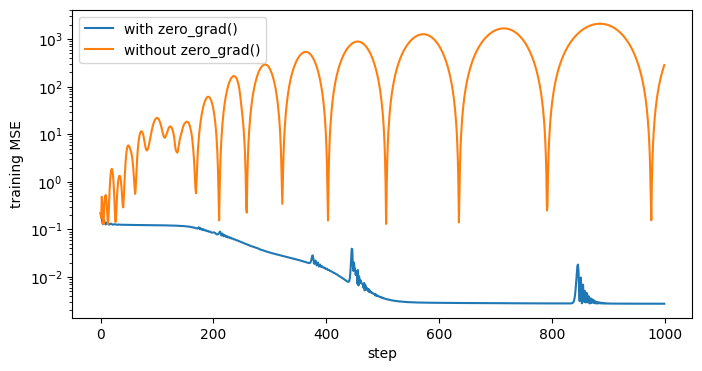

In [38]:
fig, ax = plt.subplots(figsize=(8, 4))
for reset in [True, False]:
    torch.manual_seed(1)
    m = make_mlp([1, 32, 32, 1])
    opt = torch.optim.Adam(m.parameters(), lr=1e-2)
    hist = []
    for step in range(1000):
        loss = loss_fn(m(X_train), Y_train)
        if reset:
            opt.zero_grad()
        loss.backward()
        opt.step()
        hist.append(loss.item())
    label = "with zero_grad()" if reset else "without zero_grad()"
    ax.semilogy(hist, label=label)
    stored = torch.cat([p.grad.flatten() for p in m.parameters()])                     # what the optimiser uses
    true = torch.cat([g.flatten() for g in torch.autograd.grad(loss_fn(m(X_train), Y_train), list(m.parameters()))])
    cosine = torch.dot(stored, true) / (stored.norm() * true.norm())
    print(f"{label:20s}: loss after 1000 steps = {hist[-1]:.2e},  |grad| of first layer = {m[0].weight.grad.norm().item():.1e},"
          f"  cosine(stored, true gradient) = {cosine.item():+.3f}")
ax.set_xlabel("step"); ax.set_ylabel("training MSE"); ax.legend(); plt.show()

Without `zero_grad()` the stored gradient becomes much larger than the true gradient (in a re-run, about two orders of magnitude; the true gradient is itself large
because the loss is large), and the loss grows instead of decreasing. The first-layer norms printed above ($2\cdot10^{2}$ against $10^{-4}$) compare the two runs,
not the stored and the true gradient of the same run.
The size alone would not harm Adam much, since Adam divides each update by a running average of the gradient size. The harm comes from the **direction**:
the stored `.grad` is the sum of all past gradients, dominated by the old ones, and no longer follows the gradient of the current loss. At the end of this run
the cosine printed above is close to $-1$: the updates point uphill. (With `zero_grad()` the cosine is positive but below 1 because the stored
gradient belongs to the parameters before the last `step()`, while the true gradient is computed after it.) No error is raised; only the loss curve reveals the bug.

### 13.3 Data in `float64`, model in `float32`
Arrays created by NumPy are `float64`; model parameters are `float32`. Mixing them raises an error in the first layer.

In [39]:
x64 = torch.tensor(scale(t_data[:5])).reshape(-1, 1)           # dtype float64, taken over from NumPy
try:
    best(x64)
except RuntimeError as e:
    print("RuntimeError:", e)
print("fixed:", tuple(best(x64.float()).shape))                 # .float() converts to float32

RuntimeError: mat1 and mat2 must have the same dtype, but got Double and Float
fixed: (5, 1)


### 13.4 Inputs on a large scale
The same network trained on the raw times $t\in[0, 10]$ instead of the rescaled $[-1, 1]$:

rescaled input [-1, 1]    final validation MSE 4.95e-03


raw input [0, 10]         final validation MSE 1.84e-02


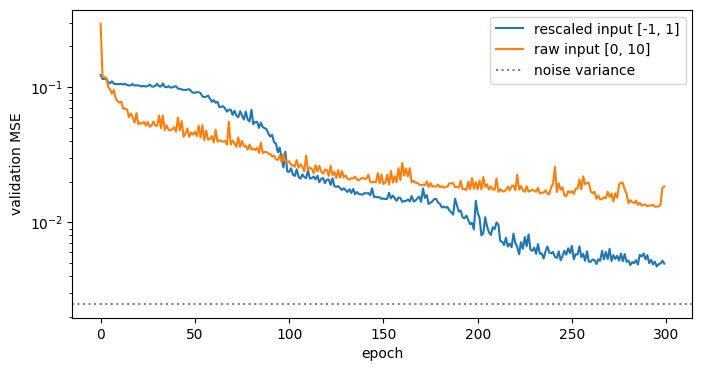

In [40]:
X_train_raw = torch.tensor(t_data[train_idx.numpy()], dtype=torch.float32).reshape(-1, 1)
X_val_raw = torch.tensor(t_data[val_idx.numpy()], dtype=torch.float32).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(8, 4))
# every value of the dictionary is a pair (training inputs, validation inputs); (Xt, Xv) unpacks the pair
for name, (Xt, Xv) in {"rescaled input [-1, 1]": (X_train, X_val), "raw input [0, 10]": (X_train_raw, X_val_raw)}.items():
    torch.manual_seed(0)
    m = make_mlp([1, 32, 32, 1])
    hist = train(m, Xt, Y_train, Xv, Y_val)
    ax.semilogy(hist["val"], label=name)
    print(f"{name:25s} final validation MSE {hist['val'][-1]:.2e}")
ax.axhline(0.05**2, color="gray", ls=":", label="noise variance")
ax.set_xlabel("epoch"); ax.set_ylabel("validation MSE"); ax.legend(); plt.show()

With the raw input the first-layer nodes $\tanh(W t + b)$ are saturated over most of the interval, their gradients are small, and the same number of epochs
gives a worse result. Rescaling inputs (and, for targets of very different size, outputs) to order one is a standard preprocessing step.

<hr/>
## 14. Training the image classifier on MNIST
Section 6 built the classifier and showed that the untrained network guesses. With the training loop of Sections 10–12 it can now be trained.
The only new ingredient is the loss function for classification.

### 14.1 Data
The 10 000 test images of Section 6 (`images`, `labels`) remain the **test set**, used once at the end. The 60 000 training images (`train=True`, already
downloaded in Section 6, since `torchvision` always downloads both parts) are split at random into 50 000 for **training** and 10 000 for **validation**.

In [41]:
try:
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        mnist_train = datasets.MNIST(root="data", train=True, download=True)
    X_all, y_all = mnist_train.data.float() / 255, mnist_train.targets
except Exception as err:
    print("MNIST training set could not be loaded:", err, " -> random images (the results below are then meaningless)")
    X_all, y_all = torch.rand(60000, 28, 28), torch.randint(0, 10, (60000,))

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(0))   # a random order of the 60 000 indices
X_tr, y_tr = X_all[perm[:50000]], y_all[perm[:50000]]                      # training set
X_va, y_va = X_all[perm[50000:]], y_all[perm[50000:]]                      # validation set
X_te, y_te = images, labels                                                # test set (Section 6)
print("training:", tuple(X_tr.shape), "  validation:", tuple(X_va.shape), "  test:", tuple(X_te.shape))

training: (50000, 28, 28)   validation: (10000, 28, 28)   test: (10000, 28, 28)


### 14.2 Loss function and accuracy
For classification the loss is the **cross-entropy** (lecture). For one image with true class $y$ and predicted probabilities
$q_k = \mathrm{softmax}(z)_k$,
$$\ell = -\log q_y ,$$
the negative logarithm of the probability that the network gives to the *correct* class: $\ell = 0$ if $q_y = 1$, and $\ell$ grows without bound as $q_y \to 0$.
The loss of a batch is the mean over its images.

`nn.CrossEntropyLoss()` (stored as `ce_loss`, so that `loss_fn`, the MSE loss of Section 10 used again in the exercises, is not overwritten) takes the **logits** of shape `(B, 10)` and the labels as integers of shape `(B,)` (dtype `int64`, which `labels` already has); it applies
the softmax itself, so the model must *not* end with a softmax layer. The label is used as an index: it picks $q_y$ out of the ten probabilities.

The **accuracy**, the fraction of correctly classified images, is what we are interested in, but it cannot be used as a loss: it changes only when an image
switches class, so its gradient with respect to the parameters is zero almost everywhere. The cross-entropy changes smoothly with the parameters.

A check before training: an untrained network gives $q_k \approx 1/10$ for every class (Section 6), so the loss should be close to $-\log(1/10) = \ln 10 \approx 2.30$.

In [42]:
ce_loss = nn.CrossEntropyLoss()

def accuracy(logits, y):
    """Fraction of images whose largest logit is at the true class."""
    return (logits.argmax(dim=1) == y).float().mean().item()

torch.manual_seed(0)
clf = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))
with torch.no_grad():
    z = clf(X_va)
    print(f"untrained: loss {ce_loss(z, y_va).item():.3f}  (ln 10 = {np.log(10):.3f}),  accuracy {accuracy(z, y_va):.3f}")

untrained: loss 2.303  (ln 10 = 2.303),  accuracy 0.108


### 14.3 The training loop
The loop is that of Section 11 with mini-batches, written out here because the loss and the recorded quantities differ:
- mini-batches of 64 images, a new random order in every epoch (`torch.randperm`), Adam with learning rate $10^{-3}$ (the default of Adam; 64 is a common batch size,
  values from 32 to 256 work as well);
- after every epoch the loss and accuracy on the training and validation sets are computed for all images at once, inside `torch.no_grad()`
  (Section 10.4). The training loss is evaluated after the epoch, with the final parameters of that epoch, so that it can be compared with the validation loss;
- 10 epochs (10 passes over the 50 000 training images). One epoch takes about a second on a CPU; the number is chosen so that the cell runs in about ten seconds
  and shows where the validation loss stops improving.

`model.train()` and `model.eval()` (Section 11.2) make no difference for this network (no dropout or batch normalisation) and are written for completeness.

In [43]:
torch.manual_seed(0)
clf = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))
optimizer = torch.optim.Adam(clf.parameters(), lr=1e-3)
batch_size, n_epochs = 64, 10
log = {"train loss": [], "val loss": [], "train acc": [], "val acc": []}

t0 = time.perf_counter()
for epoch in range(1, n_epochs + 1):
    clf.train()
    order = torch.randperm(len(X_tr))                     # new random order of the training images
    for start in range(0, len(X_tr), batch_size):
        idx = order[start:start + batch_size]             # indices of one mini-batch
        optimizer.zero_grad()
        loss = ce_loss(clf(X_tr[idx]), y_tr[idx])
        loss.backward()
        optimizer.step()

    clf.eval()
    with torch.no_grad():
        z_tr, z_va = clf(X_tr), clf(X_va)
        log["train loss"].append(ce_loss(z_tr, y_tr).item()); log["train acc"].append(accuracy(z_tr, y_tr))
        log["val loss"].append(ce_loss(z_va, y_va).item());   log["val acc"].append(accuracy(z_va, y_va))
    print(f"epoch {epoch:2d}:  loss train {log['train loss'][-1]:.4f}  val {log['val loss'][-1]:.4f}   "
          f"accuracy train {log['train acc'][-1]:.4f}  val {log['val acc'][-1]:.4f}")
print(f"training took {time.perf_counter() - t0:.0f} s")

epoch  1:  loss train 0.1856  val 0.2002   accuracy train 0.9473  val 0.9434


epoch  2:  loss train 0.1144  val 0.1393   accuracy train 0.9669  val 0.9581


epoch  3:  loss train 0.0860  val 0.1140   accuracy train 0.9747  val 0.9665


epoch  4:  loss train 0.0649  val 0.1044   accuracy train 0.9808  val 0.9691


epoch  5:  loss train 0.0504  val 0.0947   accuracy train 0.9847  val 0.9736


epoch  6:  loss train 0.0338  val 0.0844   accuracy train 0.9902  val 0.9747


epoch  7:  loss train 0.0353  val 0.0984   accuracy train 0.9891  val 0.9725


epoch  8:  loss train 0.0233  val 0.0852   accuracy train 0.9928  val 0.9753


epoch  9:  loss train 0.0205  val 0.0867   accuracy train 0.9940  val 0.9747


epoch 10:  loss train 0.0152  val 0.0898   accuracy train 0.9956  val 0.9770
training took 10 s


### 14.4 Learning curves

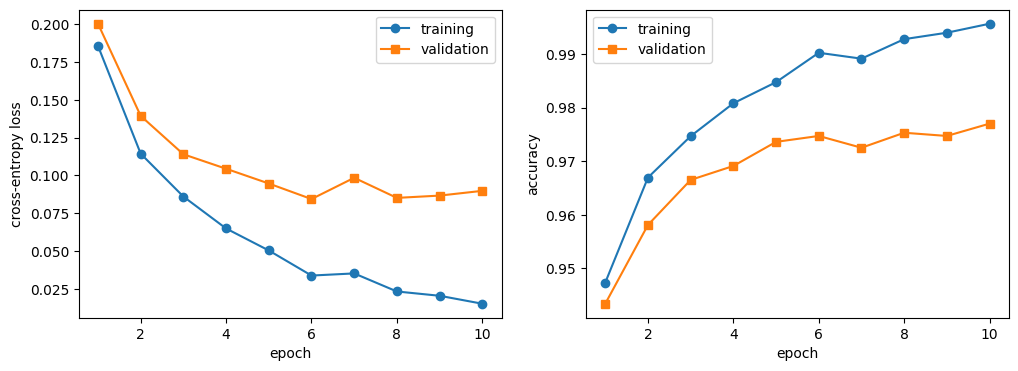

In [44]:
epochs = np.arange(1, n_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, log["train loss"], "o-", label="training")
axes[0].plot(epochs, log["val loss"], "s-", label="validation")
axes[0].set_ylabel("cross-entropy loss")
axes[1].plot(epochs, log["train acc"], "o-", label="training")
axes[1].plot(epochs, log["val acc"], "s-", label="validation")
axes[1].set_ylabel("accuracy")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend()
plt.show()

Both losses fall quickly during the first epochs. Afterwards they separate: the training loss keeps falling (from about 0.19 after the first epoch to about 0.015
after the tenth), while the validation loss reaches its smallest value after about 6 epochs (about 0.085) and then stays at that level or rises slightly. This is
the onset of **overfitting**: the network begins to adapt to details of the 50 000 training images that do not carry over to new images. The same is seen in
the accuracies: about 99.6% on the training set but about 97.7% on the validation set.

The validation *accuracy* still increases a little while the validation *loss* no longer decreases. The two measure different things: the accuracy counts only
whether the largest probability is at the right class, the cross-entropy also measures how confident the network is. As training continues, the network gets a few more images right,
but it also becomes more confident everywhere, and pays a large loss $-\log q_y$ for every image on which it is confidently wrong.

### 14.5 Evaluation on the test set
The test set is used once, for the final numbers. Besides the accuracy two views show *which* mistakes the network makes:
- the **confusion matrix** $C_{ij}$, the number of test images of true class $i$ that were classified as $j$. Correct answers lie on the diagonal. It is computed
  with one `bincount`: the pair $(i, j)$ is encoded as the single number $10i + j$, the occurrences of every number $0, \dots, 99$ are counted, and the counts are
  arranged as a $10\times10$ matrix with `reshape`;
- a few misclassified images with their true and predicted classes.

test accuracy: 0.9756   (244 of 10000 test images misclassified)


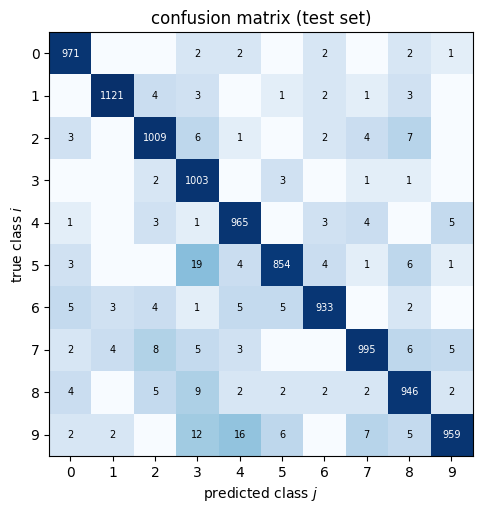

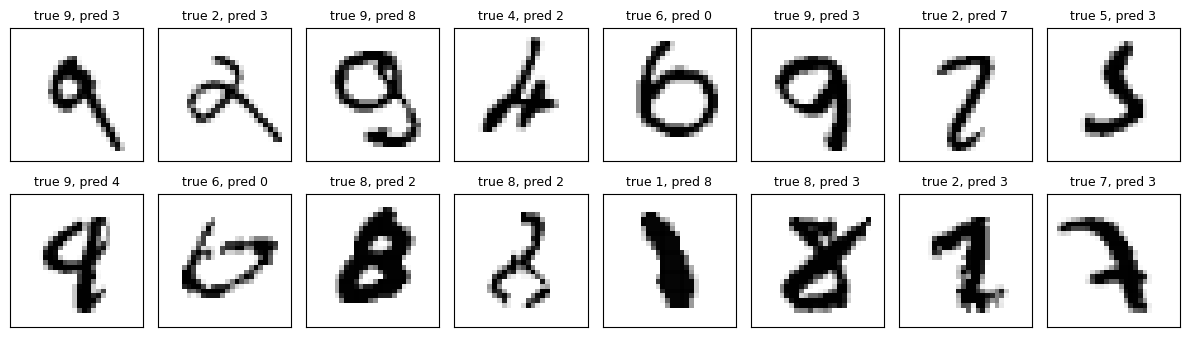

In [45]:
with torch.no_grad():
    pred_te = clf(X_te).argmax(dim=1)
print(f"test accuracy: {(pred_te == y_te).float().mean().item():.4f}   ({(pred_te != y_te).sum().item()} of {len(y_te)} test images misclassified)")

C = torch.bincount(10 * y_te + pred_te, minlength=100).reshape(10, 10)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(torch.log10(C + 1), cmap="Blues")         # logarithmic colours: the diagonal (about 1000) would hide the rest
for i in range(10):
    for j in range(10):
        if C[i, j] > 0:
            ax.text(j, i, str(C[i, j].item()), ha="center", va="center", fontsize=7,
                    color="white" if i == j else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("predicted class $j$"); ax.set_ylabel("true class $i$"); ax.set_title("confusion matrix (test set)")
plt.show()

wrong = torch.nonzero(pred_te != y_te)[:, 0]             # positions of the misclassified test images
fig, axes = plt.subplots(2, 8, figsize=(12, 3.6))
for ax, k in zip(axes.flat, wrong[:16]):
    ax.imshow(images_raw[k], cmap="gray_r")
    ax.set_title(f"true {y_te[k].item()}, pred {pred_te[k].item()}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); plt.show()

The test accuracy (about 97.5%, i.e. about 250 misclassified images out of 10 000) agrees with the validation accuracy of the last epoch: since neither set was
used for training, both estimate the accuracy on new images.

In the confusion matrix almost all images lie on the diagonal. The largest off-diagonal entries in our run are true 5 classified as 3, true 9 classified as 4,
and true 9 classified as 3: pairs of digits whose shapes are similar. The misclassified images show that a part of the mistakes concerns digits that are
hard to read also for a human; others are well readable and are genuine errors of the network.

The network reaches this accuracy without any notion that the input is an image: it treats the 784 pixels as an unordered list of numbers. Convolutional
networks, which use the two-dimensional arrangement of the pixels, reach above 99% on MNIST; they are the subject of a later lecture.

<hr/>
## 15. Summary
- A dense network is defined by its layer sizes $[n_0,\dots,n_L]$ and activation; layer $l$ has a weight matrix $n_l\times n_{l-1}$ and a bias vector of length $n_l$.
- `nn.Sequential(...)` builds a chain of layers; a class derived from `nn.Module` (layers in `__init__`, computation in `forward`) builds any architecture.
  Both are used in the same way: `model(x)`, `model.parameters()`, `model.state_dict()`.
- Networks of arbitrary depth are built in a loop: a list of layers passed to `nn.Sequential(*layers)`, or an `nn.ModuleList` in a class
  (never a plain Python list).
- Training step: forward, loss, `zero_grad()`, `backward()`, `step()`. Mini-batches via `DataLoader`; one epoch = one pass over the training data.
- Three data sets: training (fit the parameters), validation (monitor, choose), test (final estimate, used once).
- Monitor the validation loss inside `torch.no_grad()`; use `model.train()` / `model.eval()`; save with `torch.save(model.state_dict(), ...)`.
- Check shapes (`(B, 1)` vs `(B,)`), dtypes (`float32`) and the scale of the inputs.
- Classification (Section 14): one output per class, `nn.CrossEntropyLoss` on the logits with integer labels, accuracy and confusion matrix for evaluation.
<hr/>
## 16. Exercises

### Exercise 1 — One architecture, three constructions
Build the network with layer sizes $[2, 32, 32, 1]$ and $\tanh$ activations in three ways: (a) `nn.Sequential` written out layer by layer, (b) `make_mlp`,
(c) the class `MLP` of Section 7.2. Draw it with `draw_network`, check that all three have the same number of parameters, and compare it with the formula
$\sum_l n_l(n_{l-1}+1)$. Then copy the parameters of (a) into (c) and verify that both give the same output for a batch of 10 random points.
*Hint:* the `Linear` layers of (a) are `model_a[0]`, `model_a[2]`, `model_a[4]`; those of (c) are `model_c.layers[0]`, `[1]`, `[2]`.

#### Solution

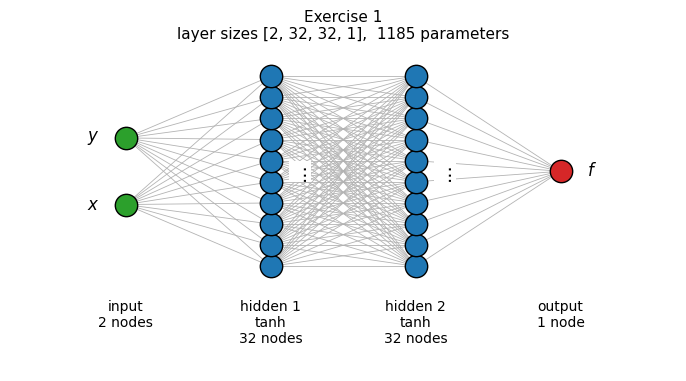

(a) Sequential by hand    parameters = 1185
(b) make_mlp              parameters = 1185
(c) MLP class             parameters = 1185
formula: 1185 = 32*(2+1) + 32*(32+1) + 1*(32+1)
max |output (a) - output (c)|: 0.0


In [47]:
sizes = [2, 32, 32, 1]
draw_network(sizes, activations=["tanh", "tanh"], title="Exercise 1", input_labels=["$x$", "$y$"], output_labels=["$f$"])
plt.show()

# (a) written out layer by layer
model_a = nn.Sequential(nn.Linear(2, 32), nn.Tanh(), nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 1))
# (b) from the list of layer sizes
model_b = make_mlp(sizes)
# (c) the class with nn.ModuleList
model_c = MLP(sizes)

formula = sum(n_out * (n_in + 1) for n_in, n_out in zip(sizes[:-1], sizes[1:]))
for name, m in [("(a) Sequential by hand", model_a), ("(b) make_mlp", model_b), ("(c) MLP class", model_c)]:
    print(f"{name:25s} parameters = {sum(p.numel() for p in m.parameters())}")
print("formula:", formula, "= 32*(2+1) + 32*(32+1) + 1*(32+1)")

# copy the parameters of (a) into (c): Linear layers of (a) are at positions 0, 2, 4 (the others are activations)
with torch.no_grad():
    for layer_c, layer_a in zip(model_c.layers, [model_a[0], model_a[2], model_a[4]]):
        layer_c.weight.copy_(layer_a.weight)
        layer_c.bias.copy_(layer_a.bias)
points = torch.rand(10, 2)
with torch.no_grad():
    print("max |output (a) - output (c)|:", (model_a(points) - model_c(points)).abs().max().item())

### Exercise 2 — Fitting a function of two variables
Fit the 2D double-well potential $V(x, y) = (x^2 - 1)^2 + \tfrac12 y^2$ on $[-1.5, 1.5]\times[-1.5, 1.5]$.
1. Generate 2000 random points $(x, y)$ in the square with values $V(x,y)$ and split them into training (1400), validation (300) and test (300) sets.
   Inputs have shape `(B, 2)`, targets `(B, 1)`.
2. Train `make_mlp([2, 64, 64, 1])` with the function `train` of Section 12 (mini-batches of 64, 200 epochs, `lr=1e-2`). Plot training and validation loss versus epoch.
3. Compute the test MSE once at the end. Show the true potential, the network and their difference as images on a $100\times100$ grid.

The inputs $x, y\in[-1.5, 1.5]$ and the values $V\in[0, 2.7]$ are already of order one, so no rescaling is needed. A function of two variables needs more
samples than one of a single variable to cover its domain, hence 2000 points and a somewhat wider network. The batch size, the number of
epochs and the learning rate are reasonable defaults, not tuned values: changing any one of them by a factor of 2–3 (measured: batch 32 or 128, 100 or 400 epochs,
`lr` $3\cdot10^{-3}$ or $3\cdot10^{-2}$) gives final validation errors between $1\cdot10^{-4}$ and $2\cdot10^{-3}$, all small compared with the range of $V$.

#### Solution

training took 4 s
final training MSE 8.47e-04, validation MSE 8.06e-04, test MSE 6.87e-04


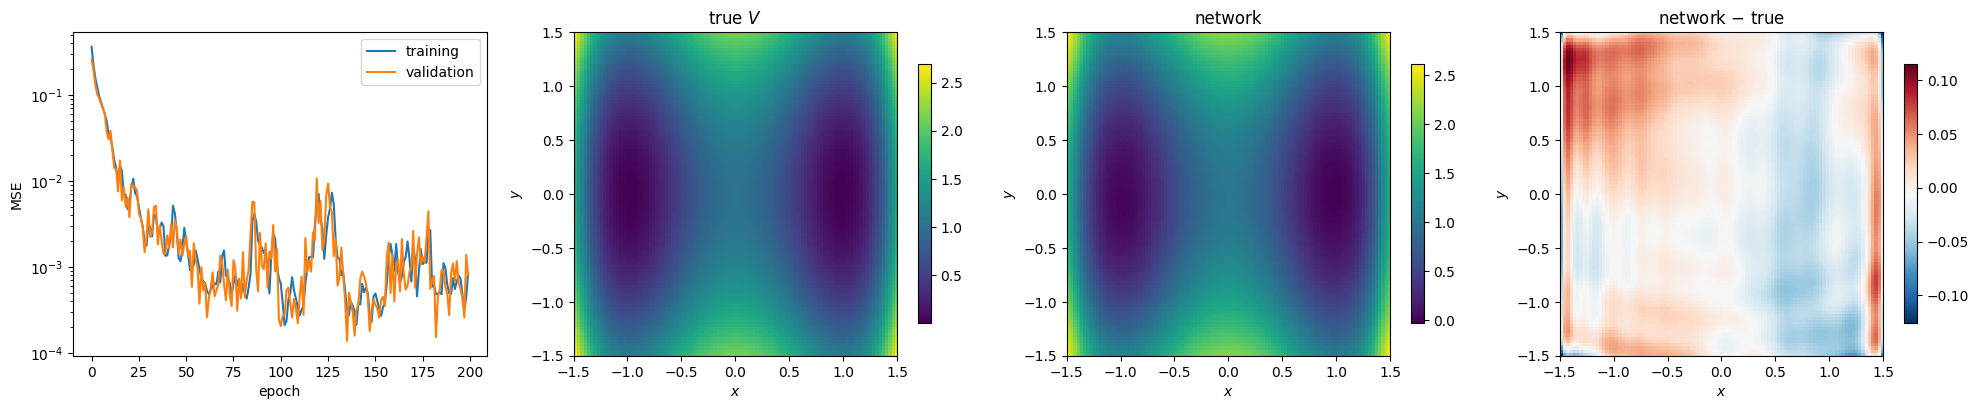

In [48]:
def V2d(x, y):
    return (x**2 - 1)**2 + 0.5 * y**2

# 1) data: random points in the square, split 1400 / 300 / 300
rng2 = np.random.default_rng(1)
P = rng2.uniform(-1.5, 1.5, size=(2000, 2))                  # each row is a point (x, y)
Z = V2d(P[:, 0], P[:, 1])
X2 = torch.tensor(P, dtype=torch.float32)                    # shape (2000, 2)
Y2 = torch.tensor(Z, dtype=torch.float32).reshape(-1, 1)     # shape (2000, 1)
X2_train, X2_val, X2_test = X2[:1400], X2[1400:1700], X2[1700:]   # the points are already in random order
Y2_train, Y2_val, Y2_test = Y2[:1400], Y2[1400:1700], Y2[1700:]

# 2) training
torch.manual_seed(0)
model_2d = make_mlp([2, 64, 64, 1])
t0 = time.perf_counter()
hist_2d = train(model_2d, X2_train, Y2_train, X2_val, Y2_val, n_epochs=200, batch_size=64, lr=1e-2)
print(f"training took {time.perf_counter() - t0:.0f} s")

# 3) test loss (once) and images
model_2d.eval()
with torch.no_grad():
    test_mse = loss_fn(model_2d(X2_test), Y2_test).item()
print(f"final training MSE {hist_2d['train'][-1]:.2e}, validation MSE {hist_2d['val'][-1]:.2e}, test MSE {test_mse:.2e}")

g1 = np.linspace(-1.5, 1.5, 100)
GX, GY = np.meshgrid(g1, g1)
# ravel() turns each 100 x 100 grid into a list of 10 000 numbers; stack(..., axis=1) puts them side by side as the
# columns x and y, giving the batch of shape (10000, 2) that the network expects. reshape(100, 100) undoes this for the image.
grid_points = torch.tensor(np.stack([GX.ravel(), GY.ravel()], axis=1), dtype=torch.float32)
with torch.no_grad():
    V_net = model_2d(grid_points).numpy().reshape(100, 100)
V_true = V2d(GX, GY)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].semilogy(hist_2d["train"], label="training"); axes[0].semilogy(hist_2d["val"], label="validation")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("MSE"); axes[0].legend()
for ax, img, title in zip(axes[1:], [V_true, V_net, V_net - V_true], ["true $V$", "network", "network $-$ true"]):
    im = ax.imshow(img, origin="lower", extent=[-1.5, 1.5, -1.5, 1.5], cmap="viridis" if title != "network $-$ true" else "RdBu_r")
    fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title(title); ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
fig.tight_layout(); plt.show()
# The square root of the test MSE is the typical error of the network in the units of V: about 0.03,
# compared with values of V between 0 and 2.7. The difference image shows where these errors are located.

### Exercise 3 — A classification task
Points $(x, y)$ belong to class 0 if their distance from the origin is below 1 and to class 1 if it is between 1.3 and 2 (two rings, no point in between).
1. Generate 600 points of each class (sample the radius uniformly in the ring and the angle uniformly), shuffle them and split 800 / 200 / 200.
2. Train `make_mlp([2, 16, 16, 2])` (two outputs = two class scores) with `nn.CrossEntropyLoss`, which takes the scores of shape `(B, 2)` and the integer
   labels of shape `(B,)` (dtype `torch.long`), and applies softmax internally. One score per class (rather than a single output) makes the same code work
   for any number of classes. The labels are integers because the loss uses them as indices, to pick the score of the correct class. Use Adam, `lr=1e-2`, full batch, 300 steps; record training and validation loss.
3. Report the accuracy (fraction of correctly classified points) on the validation and, at the end, on the test set.
4. Plot the decision boundary: the predicted class on a grid of points, with the data on top.

(The function `train` of Section 12 uses `nn.MSELoss`; write the loop by hand here.)

#### Solution

validation accuracy: 1.000
test accuracy (computed once at the end): 1.000


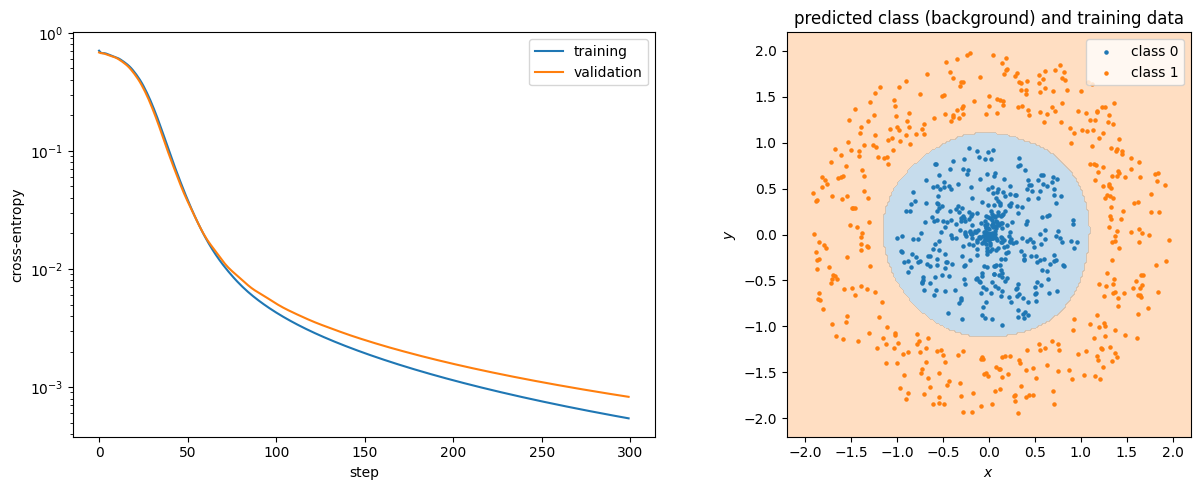

In [49]:
# 1) data: two rings
rng3 = np.random.default_rng(2)
def ring(n, r_min, r_max):
    r = rng3.uniform(r_min, r_max, n)
    phi = rng3.uniform(0, 2 * np.pi, n)
    return np.stack([r * np.cos(phi), r * np.sin(phi)], axis=1)

points_rings = np.concatenate([ring(600, 0.0, 1.0), ring(600, 1.3, 2.0)])
labels_rings = np.concatenate([np.zeros(600), np.ones(600)])
order = rng3.permutation(1200)                                      # shuffle points and labels together
Xc = torch.tensor(points_rings[order], dtype=torch.float32)
Yc = torch.tensor(labels_rings[order], dtype=torch.long)                  # integer class labels, shape (1200,)
Xc_train, Xc_val, Xc_test = Xc[:800], Xc[800:1000], Xc[1000:]
Yc_train, Yc_val, Yc_test = Yc[:800], Yc[800:1000], Yc[1000:]

# 2) model and training loop
torch.manual_seed(0)
clf_rings = make_mlp([2, 16, 16, 2])                                      # outputs: one score (logit) per class
ce_loss_rings = nn.CrossEntropyLoss()
opt = torch.optim.Adam(clf_rings.parameters(), lr=1e-2)
hist_tr, hist_va = [], []
for step in range(300):
    loss = ce_loss_rings(clf_rings(Xc_train), Yc_train)                         # scores (800, 2) vs labels (800,)
    opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        hist_va.append(ce_loss_rings(clf_rings(Xc_val), Yc_val).item())
    hist_tr.append(loss.item())

# 3) accuracy: the predicted class is the one with the larger score.
# argmax(dim=1) gives, for every row, the index of the largest entry. Softmax does not change the order of the
# scores, so this is also the class of highest probability, and softmax need not be computed.
# (... == Y) is a tensor of True/False; .float() turns it into 1.0/0.0, and its mean is the fraction of correct answers.
def accuracy_of(model, X, Y):
    with torch.no_grad():
        return (model(X).argmax(dim=1) == Y).float().mean().item()
print(f"validation accuracy: {accuracy_of(clf_rings, Xc_val, Yc_val):.3f}")
print(f"test accuracy (computed once at the end): {accuracy_of(clf_rings, Xc_test, Yc_test):.3f}")
# The two classes are separated by an empty ring (1 < r < 1.3), so a perfect classification is possible.
# Without the gap (e.g. class 1 for 1 < r < 2) points near r = 1 would be harder, and the accuracy would drop below 1.

# 4) decision boundary
g = np.linspace(-2.2, 2.2, 200)
GX, GY = np.meshgrid(g, g)
grid = torch.tensor(np.stack([GX.ravel(), GY.ravel()], axis=1), dtype=torch.float32)
with torch.no_grad():
    pred_class = clf_rings(grid).argmax(dim=1).numpy().reshape(200, 200)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(hist_tr, label="training"); axes[0].plot(hist_va, label="validation")
axes[0].set_yscale("log"); axes[0].set_xlabel("step"); axes[0].set_ylabel("cross-entropy"); axes[0].legend()
# the classes are the integers 0 and 1: boundaries at -0.5, 0.5, 1.5 give exactly one colour to each class
axes[1].contourf(GX, GY, pred_class, levels=[-0.5, 0.5, 1.5], colors=["C0", "C1"], alpha=0.25)
# Xc_train[Yc_train == 0]: indexing with a True/False tensor keeps the rows where the condition holds (shape (n, 2));
# .T turns it into two rows x and y, and * passes them as the two arguments of scatter
axes[1].scatter(*Xc_train[Yc_train == 0].T, s=5, color="C0", label="class 0")
axes[1].scatter(*Xc_train[Yc_train == 1].T, s=5, color="C1", label="class 1")
axes[1].set_aspect("equal"); axes[1].set_xlabel("$x$"); axes[1].set_ylabel("$y$"); axes[1].legend(loc="upper right")
axes[1].set_title("predicted class (background) and training data")
fig.tight_layout(); plt.show()

### Exercise 4 — Boundary conditions built into the network
The ground state of a particle in a box $[0, 1]$ is $\psi_\ast(x) = \sqrt2\sin(\pi x)$. Fit it from 15 noisy samples ($\sigma = 0.05$) at random points in $[0, 1]$
with (a) `BoxWavefunction([1, 16, 16, 1])` of Section 8.2 and (b) an unconstrained `make_mlp([1, 16, 16, 1])`. Train both with Adam (`lr=1e-2`, full batch, 2000 steps).
Compare the values at $x = 0$ and $x = 1$ and the maximal error on a dense grid, and plot both fits. Which model respects the physics, and where does the
unconstrained one go wrong?

Few samples are used on purpose: the regions between the outermost samples and the walls are then not covered by data, which exposes the difference
between the two models.

#### Solution

x(1-x) NN(x)         psi(0) = +0.000   psi(1) = +0.000   max |error| = 0.082
unconstrained NN(x)  psi(0) = -0.035   psi(1) = +0.793   max |error| = 0.793


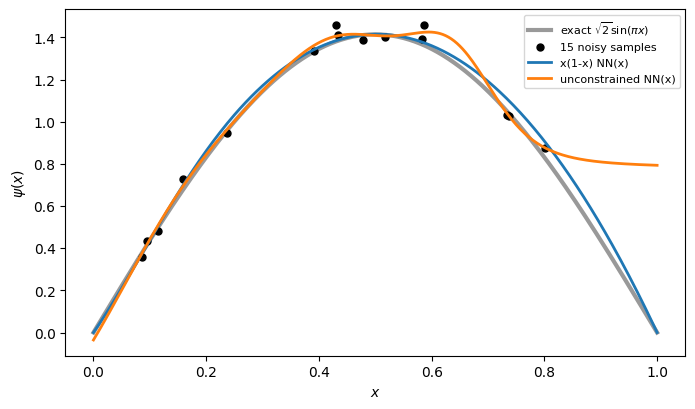

In [50]:
rng4 = np.random.default_rng(3)
x_s = np.sort(rng4.uniform(0, 1, 15))
y_s = np.sqrt(2) * np.sin(np.pi * x_s) + 0.05 * rng4.normal(size=15)
Xs = torch.tensor(x_s, dtype=torch.float32).reshape(-1, 1)
Ys = torch.tensor(y_s, dtype=torch.float32).reshape(-1, 1)

def fit(model, steps=2000):
    opt = torch.optim.Adam(model.parameters(), lr=1e-2)
    for _ in range(steps):
        loss = loss_fn(model(Xs), Ys)
        opt.zero_grad(); loss.backward(); opt.step()
    return model

torch.manual_seed(0); constrained = fit(BoxWavefunction([1, 16, 16, 1]))
torch.manual_seed(0); free = fit(make_mlp([1, 16, 16, 1]))

x_dense = torch.linspace(0, 1, 401).reshape(-1, 1)
exact = np.sqrt(2) * np.sin(np.pi * x_dense.numpy())
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x_dense, exact, "k", lw=3, alpha=0.4, label=r"exact $\sqrt{2}\sin(\pi x)$")
ax.plot(x_s, y_s, "ko", ms=5, label="15 noisy samples")
for name, m in [("x(1-x) NN(x)", constrained), ("unconstrained NN(x)", free)]:
    with torch.no_grad():
        values = m(x_dense).numpy()
    ax.plot(x_dense, values, lw=2, label=name)
    print(f"{name:20s} psi(0) = {values[0, 0]:+.3f}   psi(1) = {values[-1, 0]:+.3f}   max |error| = {np.max(np.abs(values - exact)):.3f}")
ax.set_xlabel("$x$"); ax.set_ylabel(r"$\psi(x)$"); ax.legend(fontsize=8); plt.show()
# The constrained model vanishes exactly at both walls for any parameters. The unconstrained model is only
# determined where there are samples; between the outermost samples and the walls it is not forced to zero.

### Exercise 5 (advanced) — Deep plain network vs. residual network
Train on the damped-oscillation data of Section 10 two networks of the same depth (10 hidden layers of width 16): `make_mlp([1] + [16] * 10 + [1])` and
`ResidualMLP(1, 16, 9, 1)` (one input layer plus 9 residual blocks), both with `train` (300 epochs). Plot their validation losses versus epoch.
Before training, print the norm of the gradient of the first layer's weights for both models (one backward pass on the training set): what does it tell us about
how the signal propagates backwards through a deep plain network?

#### Solution

parameters: plain 2497   residual 2497
plain     |dL/dW of first layer| = 8.37e-05
residual  |dL/dW of first layer| = 4.23e-01


plain, 10 hidden layers   final validation MSE 1.50e-02


residual, 9 blocks        final validation MSE 5.15e-03


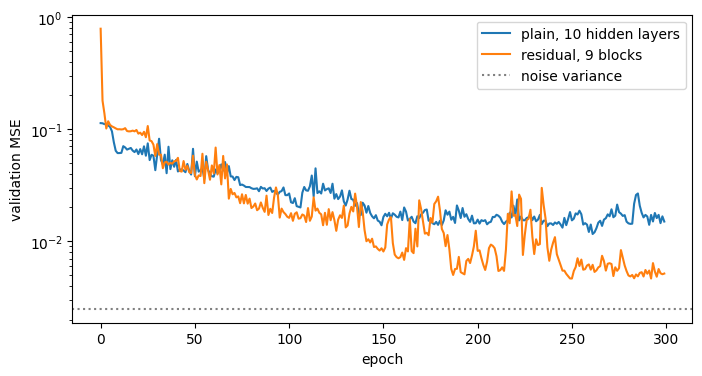

In [51]:
torch.manual_seed(0); plain = make_mlp([1] + [16] * 10 + [1])
torch.manual_seed(0); resnet = ResidualMLP(1, 16, 9, 1)
print("parameters: plain", sum(p.numel() for p in plain.parameters()), "  residual", sum(p.numel() for p in resnet.parameters()))

# gradient of the first layer before training
for name, m, first in [("plain", plain, plain[0]), ("residual", resnet, resnet.input_layer)]:
    m.zero_grad()
    loss_fn(m(X_train), Y_train).backward()
    print(f"{name:9s} |dL/dW of first layer| = {first.weight.grad.norm().item():.2e}")

fig, ax = plt.subplots(figsize=(8, 4))
for name, m in [("plain, 10 hidden layers", plain), ("residual, 9 blocks", resnet)]:
    hist = train(m, X_train, Y_train, X_val, Y_val, n_epochs=300)
    ax.semilogy(hist["val"], label=name)
    print(f"{name:25s} final validation MSE {hist['val'][-1]:.2e}")
ax.axhline(0.05**2, color="gray", ls=":", label="noise variance")
ax.set_xlabel("epoch"); ax.set_ylabel("validation MSE"); ax.legend(); plt.show()
# In the plain network the gradient reaching the first layer is the product of many factors (one per layer), each
# typically smaller than one for tanh with the default initialisation: it is much smaller than in the residual network,
# where the skip connections pass the gradient directly. This is the vanishing-gradient problem.